# 342. Does a pattern label from Swiss-Prot predict what an alternative exon does?

An alternative exon adds or removes 10 to 150 residues from a protein. Four kinds of label can
say what that stretch does, from most to least settled:

1. **Folded-domain overlap.** The exon's residues sit inside a Pfam domain.
2. **Short motifs and modification sites.** An ELM motif, or a UniProt modified residue
   (MOD_RES), inside the exon.
3. **Composition and pattern class.** Disorder (IUPred), κ (how evenly positive and negative
   residues are mixed: 0 when they alternate, 1 when they sit apart), Ω_aro (the same measure for
   aromatic residues against all others), net charge, the share of each residue class, and
   low-complexity stretches.
4. **Pattern label transferred from a database.** The exon's residues share an exact k-mer, in a
   reduced alphabet, with an annotated region of another protein (a Swiss-Prot REGION, COMPBIAS,
   MOTIF, REPEAT, ZN_FING, COILED or DOMAIN feature). kmerseek finds these.

Kinds 1 to 3 need no search. Only kind 4 needs a k-mer index.

**Question.** Does the kind 4 label predict whether neurons include or skip an exon more than
progenitors do, beyond what kinds 1 to 3 already predict?

**What this decides.** A pass supports testing transferred k-mer labels on a second outcome
(TDP-43 loss in motor neurons, Tanaka et al. 2025) and a second index (PhaSePro and DisProt
regions). If both comparisons fail, this experiment does not support adding those labels
to the set A splicing classifier.

### Prior work

Tranchevent, Léon-Charles, Fabien Aubé, Louis Dulaurier, et al. "Identification of Protein
Features Encoded by Alternative Exons Using Exon Ontology." *Genome Research* 27, no. 6 (2017):
1087–97. https://doi.org/10.1101/gr.212696.116.

**Note.** Exon Ontology already labels exons with kinds 1 to 3. This notebook does not rebuild it.
It adds kind 4 and tests it.

Buljan, Marija, Guilhem Chalancon, Sebastian Eustermann, et al. "Tissue-Specific Splicing of
Disordered Segments That Embed Binding Motifs Rewires Protein Interaction Networks." *Molecular
Cell* 46, no. 6 (2012): 871–83. https://doi.org/10.1016/j.molcel.2012.05.039.

**Note.** Tissue-specific exons code for disordered segments rich in modification sites and
binding motifs. This is the positive control (rule 2 below).

### The example exon: ZNF207 (BuGZ) exon 9

chr17:32,366,665–32,366,757 (GRCh38, Ensembl 116), residues 277–307 of ZNF207-203, 93 nt, starts
in phase 0, keeps the reading frame:

```
MGTPVTSSSTASSNSESLSASSKALFPSTAQ
```

11 serines of 31 residues, 1 aromatic residue (F302), 2 charged residues, IUPred mean 0.78
(IUPred run on the whole isoform, averaged over the exon), pI 5.8. In `aro_hyd_chg_pol4`, 20 of its
31 residues are polar (`s`) and 8 are other hydrophobic (`a`). Section 0 prints it in every alphabet searched, so the reader can see
which alphabets have anything to match. The alphabets were not chosen from this exon.

In set A ([notebook 341](https://github.com/seanome/2024-kmerseek-analysis/blob/olgabot/condensate-exons-341/notebooks/341_condensate_exons_aro_hyd_chg_pol4_bugz.ipynb),
section 3b), neurons include it more in all three donors. Ψ is 0.95 in the germinal zone against
0.99 in the cortical plate, then 0.91 against 0.97, then 0.91 against 0.97. Each of those
changes is under 0.10, so under the outcome rule below it is in no class and is left out of the
test. Section 1 prints its class.

### Data

| what | source | version and check |
|---|---|---|
| Set A isoforms and read counts | Patowary et al. 2024, Dryad doi:10.5061/dryad.0rxwdbs68: Data S1 (`Bulk.gtf`, GRCh37) and Data S2 sheet B (counts per isoform, 3 donors × 4 replicates in each of germinal zone and cortical plate) | downloaded 2026-10-14; SHA-256 printed in section 0 |
| Genome for the isoform proteins | GENCODE release 33, GRCh37 primary assembly | md5 c9f86b6083dd05b9799eca02c79f651d |
| Exon event table | `scripts/build_341_exon_table.py` (notebook 341, [PR 140](https://github.com/seanome/2024-kmerseek-analysis/pull/140)), run on Sherlock as Slurm job 47934291, 2026-10-15: 12 min, 2.5 GB peak | md5 printed in section 0 |
| Regions index | [PR 114](https://github.com/seanome/2024-kmerseek-analysis/pull/114): Swiss-Prot 2026_03 minus Mammalia, every annotated feature cut out with flanks, rebuilt at k_max 22 on 2026-10-13 (640_927 entries, 46_921_644 target residues, 10-residue decoy windows, decoy md5 1dd147349181efd1df7f3990b0883d5f) | to be checked in Stop 3 |
| Query decoys | `dipeptide_shuffle` in `nextflow-runs/shared/decoys.py` ([PR 138](https://github.com/seanome/2024-kmerseek-analysis/pull/138)) | imported in Stop 3 |
| Copy rate κ and penalty C for the two new alphabets | `scripts/342_kappa_new_alphabets.py` on notebook 230's Pfam-A 38.2 seed pairs, then `tools/kappa-for-alphabet` from olgabot/dark-set-kmerseek-0.4 (ec91da5) | printed in section 0 |

The prompt for this notebook gave the regions index as 639_854 entries. That is the k_max 21
build. The k_max 22 rebuild has 640_927 entries; Stop 3 uses the k_max 22 build and prints its
entry count.

### What had been seen before these rules were written

From notebook 341 (PR 140): the event table has 30_548 one-exon events in 8_890 genes. 7_500 of
them keep the frame with the exon inside the ORF, and 7_062 of those have proteins that differ
only by the exon. Under notebook 341's own rule (at least 10 reads per donor and region, all
three donors in the same direction, mean change at least 0.1), 658 exons change: 431 included
more in neurons and 227 less. The ZNF207 exon 9 numbers above were also seen. No count under the
rule below, no unchanged-class count, and no label of any kind on any exon except ZNF207 exon 9
had been seen.

### Rule 1: the outcome per exon

* Ψ (percent spliced in) per donor per region = reads of including isoforms / (reads of including
  plus skipping isoforms), each summed over the four replicates.
* ΔΨ = Ψ(cortical plate) − Ψ(germinal zone), per donor. The cortical plate holds neurons, the
  germinal zone holds progenitors.
* **Included more in neurons**: ΔΨ > +0.10 in all three donors.
* **Skipped more in neurons**: ΔΨ < −0.10 in all three donors.
* **Unchanged**: |ΔΨ| < 0.05 in all three donors.
* Any other exon is left out of the test and counted in the funnel.
* Only events with at least 20 reads (including plus skipping) in both regions in every donor.
* Only events whose two proteins are the same apart from the exon (`orf_otherwise_identical`),
  whose exon keeps the frame, and whose exon codes for 10 to 150 residues.

### Rule 2: tune and test halves

Genes, not exons, are split in half at random (numpy seed 342) before any label is computed. All
exons of a gene go to the same half. Every choice (the C value of the model, the decoy cutoff of
each kmerseek setting) is made on the tune half. The test half is read once, at the end.

### Rule 3: the positive control (Buljan et al. 2012)

On the tune half, exons in the two changed classes, pooled, have a higher mean IUPred score than
unchanged exons. The statistic is the difference of the two class means (changed minus
unchanged), with a 95% interval from 10_000 bootstrap resamples of genes. It holds if the whole
interval is above 0. If it fails, the notebook stops: the exon table or the outcome rule is wrong.

### Rule 4: the kill test

On the test half, a logistic regression tells "included more in neurons" from "unchanged".
Model 3 uses the kind 1 to 3 features. Model 4 uses the same features plus the kind 4 features.
Both are fit on the tune half (standardized features, L2 penalty, its strength chosen by 5-fold
cross-validation with folds split by gene) and then scored once on the test half.

* The statistic is the AUROC gain, model 4 minus model 3, on the test half, with a 95% interval
  from 10_000 bootstrap resamples of test genes. AUROC is the chance that a random exon of the
  changed class gets a higher score than a random unchanged exon: 0.5 is no signal, higher is
  better.
* **PASS** if the whole interval is at or above 0.02.
* **KILL** if the whole interval is below 0.02.
* **Unclear** if the interval contains 0.02. The notebook then gives the number of test exons
  that would make the interval narrow enough to decide, and says whether set A has that many.
* The same test is run for "skipped more in neurons" against "unchanged". Each comparison gets its
  own verdict. This test supports kmerseek for the set A splicing task if at least one comparison passes. Neither comparison supports this application if both are KILL. Any other pair of verdicts is unclear.
* A missing feature value (Ω_aro on an exon with 10% or fewer aromatic residues; no kind 4 hit) is
  set to 0 and gets its own 0/1 column saying it was missing.
* Power: with fewer than 100 exons of a changed class on the tune half, the test is unlikely to
  resolve a gain of 0.02. Section 1 says so if that happens.

### Predictions, written now

* **P1.** The positive control holds: changed exons have a higher mean IUPred score than unchanged
  ones, and the 95% interval of the difference is above 0.
* **P2.** Fewer than 30% of exons get any kind 4 hit at E < 1 (a hit, in any of the four kmerseek
  settings, on a real Swiss-Prot entry, whose query coordinates overlap at least one exon
  residue). The exon queries are short, so they carry few k-mers.
* **P3.** The kind 4 score is mostly explained by kind 3 features: Spearman |ρ| above 0.5 between
  −log10(best E) and at least one of IUPred mean, other-hydrophobic fraction (AILMV) or
  low-complexity fraction, over exons with a hit. The expected one is the low-complexity fraction.
* **P4.** KILL. Model 4 adds less than 0.02 AUROC in both comparisons. The notebook is built so
  that this prediction can fail.

### kmerseek settings

A kmerseek setting is one alphabet, k-mer size k, scaled, extension penalty and mask. All four use
scaled 1, mask off, extension with the alphabet's own mismatch penalty C, and X-drop 4 × C (the
dark-set run's rule). The other search options are PR 114's (`--threshold 0.0
--min-shared-kmers 2 --max-query-pvalue 0.05 --min-region-score 1.3 --chain-max-gap 30
--chain-max-shift 10`).

| alphabet | classes | k | penalty C | X-drop | source of C |
|---|---|---|---|---|---|
| aro_hyd_chg_pol4 | FWY, AILMV, DEKR, SNQTGCPH | 11 | 0.58 | 2.32 | computed here (section 0) |
| aro_hyd_arg_chg_pol5 | FWY, AILMV, R, DEK, SNQTGCPH | 9 | 0.46 | 1.85 | computed here (section 0) |
| hp_pbotc_1st_ed2 | ACFILMPVWY, DEGHKNQRST | 21 | 1.59 | 6.35 | dark-set table |
| protein20 | the 20 amino acids | 5 | 0.14 | 0.57 | dark-set table |

The last two are PR 114's settings 2 and 4, so their behaviour on this index is known. C comes
from the copy rate κ, the chance-corrected share of aligned Pfam seed pairs (20–30% identity) that
put the two residues in the same class: C = −ln(1 − κ) / ln(1 + κ·n − κ) for an alphabet of n
classes. That formula assumes the classes are equally common. They are not in
`aro_hyd_chg_pol4` (FWY is about 8% of residues), the same as for every row of the dark-set table.

E-values use the Karlin-Altschul fit of the whole-protein index (kmerseek's `--ka-r-database`
route, seanome/kmerseek PR 144), as PR 114 did, because the regions index's own fit changed its
slope up to tenfold between two decoy windows of the same setting. The two new alphabets have no
whole-protein index yet, so Stop 3 builds one for the fit.

The kmerseek build must hold the two new alphabets (seanome/kmerseek PR 146) and the equal-k-mer-set
fix (seanome/kmerseek PR 141). Both PRs were open on 2026-10-16. Stop 3 records the commit and the
image digest.

**Own-gene hits.** Index entries from the query's own gene (same gene symbol in UniProt's gene
name field) are removed before kind 4 features are computed. Mammals are already out of the
index, so what this removes is the same gene in other animals. The section that asks how much of
the kind 4 signal is a self-hit counts those removed hits. Olga confirmed this on 2026-10-16, before any search had
run: model 4 sees only hits to other genes, and the hits the filter removes are counted, with
their scores, in a separate section. Matching on gene symbol misses a same-gene target whose name
differs (a fish paralog named `znf207b`, for example); that section also reports how many hits go
to targets whose name starts with the query's gene symbol.

### Order of work

* Stop 0, this cell and section 0: committed before any count is read.
* Stop 1: the exon table, the outcome classes and the halves (section 1).
* Stop 2: kinds 1 to 3, the positive control, the alphabet check.
* Stop 3: kind 4 on Sherlock.
* Stop 4: the test.

In [1]:
import hashlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

sys.path.insert(0, str(Path.cwd()))
import condensate_exon_utils as cu
import pubfig as pf

pf.use_style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_width_chars(160)

REPO = Path.cwd().parent
DATA_341 = REPO / "data" / "341_condensate_exons"
DRYAD = Path("/Users/olga/data/condensate_exons_341/patowary2024_dryad")
TABLES = REPO / "tables" / "342"
FIGURES = REPO / "figures" / "342"
FIGURES.mkdir(parents=True, exist_ok=True)

#: Seed for the gene split and every bootstrap (rule 2).
SEED = 342


def save_figure(fig, stem):
    # pf.save, then the PNG as an 8-bit palette of at most 256 colours. pf.save does the
    # palette step itself once PR 123 is merged; until then it is done here.
    pf.save(fig, stem)
    if not hasattr(pf, "to_256_colours"):
        from PIL import Image

        png = Path(stem).with_suffix(".png")
        Image.open(png).convert("RGB").quantize(
            colors=256, dither=Image.Dither.NONE
        ).save(png, optimize=True)

## 0. Inputs, the example exon and the kmerseek settings

Checksums of the inputs, the κ rows behind the two new penalties, and ZNF207 exon 9 in every
alphabet searched.

In [2]:
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def md5(path):
    return hashlib.md5(Path(path).read_bytes()).hexdigest()


# SHA-256 values listed by Dryad for doi:10.5061/dryad.0rxwdbs68 (also in notebooks/341_exon_table_setA.sbatch).
DRYAD_SHA256 = {
    "DataS1.tar.gz": "7bffff510a453a2bff7f6683bdad0140b3e5ca4e31ecda5b0ecefad498807eab",
    "DataS2.xlsx.zip": "43230bda4631add5e4257c70ef239ad6f1e57598ac8e6d042dcb5de8ccecf19f",
}
rows = []
for name, expected in DRYAD_SHA256.items():
    got = sha256(DRYAD / name)
    assert got == expected, name
    rows.append(
        {"file": f"Dryad {name}", "checksum": f"sha256 {got}", "matches source": True}
    )
EVENTS_PATH = DATA_341 / "341_setA_exon_events.parquet"
rows.append(
    {
        "file": EVENTS_PATH.name,
        "checksum": f"md5 {md5(EVENTS_PATH)}",
        "matches source": None,
    }
)
for path in sorted(TABLES.glob("*kappa*")):
    rows.append(
        {
            "file": f"tables/342/{path.name}",
            "checksum": f"md5 {md5(path)}",
            "matches source": None,
        }
    )
pl.DataFrame(rows)

file,checksum,matches source
str,str,bool
"""Dryad DataS1.tar.gz""","""sha256 7bffff510a453a2bff7f668…",true
"""Dryad DataS2.xlsx.zip""","""sha256 43230bda4631add5e4257c7…",true
"""341_setA_exon_events.parquet""","""md5 247350bb1b270f9eb0585cb457…",null
"""tables/342/230_pair_kappa_new_…","""md5 7b5ef6de45d65b41168c7e4964…",null
"""tables/342/dark_set_kappa_by_a…","""md5 d0774e68fbf8aa38cc4c2bfbfe…",null
"""tables/342/kappa_by_alphabet_n…","""md5 257f3dafbc7b54f6f07d9c89a9…",null


In [3]:
# kappa and C: the two new alphabets from scripts/342_kappa_new_alphabets.py, polarity4 recomputed
# by the same script as a check, and the two reused alphabets from the dark-set table (ec91da5).
new_rows = pl.read_csv(TABLES / "kappa_by_alphabet_new_rows.tsv", separator="\t")
dark_set = pl.read_csv(
    TABLES / "dark_set_kappa_by_alphabet.ec91da5.tsv",
    separator="\t",
    comment_prefix="#",
)
check = new_rows.filter(pl.col("alphabet") == "polarity4").drop("alphabet").row(0)
assert check == dark_set.filter(pl.col("alphabet") == "polarity4").drop("alphabet").row(
    0
)
print("polarity4 recomputed here equals the dark-set row:", check)

SETTINGS = pl.DataFrame(
    {
        "alphabet": [
            "aro_hyd_chg_pol4",
            "aro_hyd_arg_chg_pol5",
            "hp_pbotc_1st_ed2",
            "protein20",
        ],
        "k": [11, 9, 21, 5],
    }
).join(
    pl.concat([new_rows.filter(pl.col("alphabet") != "polarity4"), dark_set]),
    on="alphabet",
    how="left",
    maintain_order="left",
)
SETTINGS.select(
    "alphabet",
    "classes",
    "k",
    "kappa",
    "kappa_lo",
    "kappa_hi",
    "n_pairs",
    "c_opt",
    "xdrop_4c",
)

polarity4 recomputed here equals the dark-set row: (4, 0.2837, 0.2831, 0.2844, 37085, 0.54, 2.17)


alphabet,classes,k,kappa,kappa_lo,kappa_hi,n_pairs,c_opt,xdrop_4c
str,i64,i64,f64,f64,f64,i64,f64,f64
"""aro_hyd_chg_pol4""",4,11,0.3288,0.3281,0.3294,37085,0.58,2.32
"""aro_hyd_arg_chg_pol5""",5,9,0.3126,0.312,0.3132,37085,0.46,1.85
"""hp_pbotc_1st_ed2""",2,21,0.4389,0.438,0.4399,37085,1.59,6.35
"""protein20""",20,5,0.1988,0.1985,0.1992,37085,0.14,0.57


In [4]:
#: Class letters for printing. A class of aro_hyd_chg_pol4 or aro_hyd_arg_chg_pol5 is written as the
#: first residue of its cluster, lowercased, as kmerseek's build_reduced does (seanome/kmerseek PR 146, src/rust/alphabets.rs).
ALPHABET_CLUSTERS = {
    "protein20": list("ACDEFGHIKLMNPQRSTVWY"),
    "aro_hyd_chg_pol4": ["FWY", "AILMV", "DEKR", "SNQTGCPH"],
    "aro_hyd_arg_chg_pol5": ["FWY", "AILMV", "R", "DEK", "SNQTGCPH"],
    "hp_pbotc_1st_ed2": ["ACFILMPVWY", "DEGHKNQRST"],
}
LETTER_TABLES = {
    name: {aa: cl[0].lower() for cl in clusters for aa in cl}
    for name, clusters in ALPHABET_CLUSTERS.items()
}
LETTER_TABLES["protein20"] = {aa: aa for aa in ALPHABET_CLUSTERS["protein20"]}
# hp_pbotc_1st_ed2 is written h (hydrophobic) and p (polar), as in notebook 341.
LETTER_TABLES["hp_pbotc_1st_ed2"] = cu.HP_PBOTC_1ST_ED2
assert LETTER_TABLES["aro_hyd_chg_pol4"] == cu.ARO_HYD_CHG_POL4

HERO_GENE, HERO_ISOFORM = "ZNF207", "ZNF207-203"
HERO_FIRST = 277  # 1-based, inclusive, on ZNF207-203
HERO_LAST = 307
HERO_RESIDUES = "MGTPVTSSSTASSNSESLSASSKALFPSTAQ"
hero_protein = (DATA_341 / "ensembl_protein_ZNF207-203.txt").read_text().strip()
assert hero_protein[HERO_FIRST - 1 : HERO_LAST] == HERO_RESIDUES

print(
    f"{HERO_ISOFORM} residues {HERO_FIRST}-{HERO_LAST} (exon 9), Ensembl 116 translation\n"
)
for name, table in LETTER_TABLES.items():
    print(f"{name:>22}  {HERO_FIRST}  {cu.encode(HERO_RESIDUES, table)}  {HERO_LAST}")
print()
print(
    "aro_hyd_chg_pol4: "
    + ", ".join(
        f"{cl[0].lower()} = {cl}" for cl in ALPHABET_CLUSTERS["aro_hyd_chg_pol4"]
    )
)
print(
    "aro_hyd_arg_chg_pol5: "
    + ", ".join(
        f"{cl[0].lower()} = {cl}" for cl in ALPHABET_CLUSTERS["aro_hyd_arg_chg_pol5"]
    )
)
print("hp_pbotc_1st_ed2: h = ACFILMPVWY, p = DEGHKNQRST")
print(
    "The exon has no R, so aro_hyd_chg_pol4 and aro_hyd_arg_chg_pol5 write it the same way."
)

pol4 = cu.encode(HERO_RESIDUES, cu.ARO_HYD_CHG_POL4)
hero_stats = {
    "length (aa)": len(HERO_RESIDUES),
    "serines": HERO_RESIDUES.count("S"),
    "aromatic (FWY)": cu.aromatic_count(HERO_RESIDUES),
    "aromatic positions": [
        HERO_FIRST + i for i, aa in enumerate(HERO_RESIDUES) if aa in cu.AROMATIC
    ],
    "charged (DEKR)": sum(aa in "DEKR" for aa in HERO_RESIDUES),
    "polar class s in aro_hyd_chg_pol4": pol4.count("s"),
    "other hydrophobic class a in aro_hyd_chg_pol4": pol4.count("a"),
    "IUPred long mean, in the whole isoform": round(
        cu.iupred_mean_in_context(hero_protein, HERO_FIRST, HERO_LAST), 2
    ),
    "pI": round(cu.isoelectric_point(HERO_RESIDUES), 1),
    "isoform length (aa)": len(hero_protein),
}
print()
for key, value in hero_stats.items():
    print(f"{key:>40}: {value}")

ZNF207-203 residues 277-307 (exon 9), Ensembl 116 translation

             protein20  277  MGTPVTSSSTASSNSESLSASSKALFPSTAQ  307
      aro_hyd_chg_pol4  277  asssasssssassssdsasassdaafsssas  307
  aro_hyd_arg_chg_pol5  277  asssasssssassssdsasassdaafsssas  307
      hp_pbotc_1st_ed2  277  hpphhppppphpppppphphppphhhhpphp  307

aro_hyd_chg_pol4: f = FWY, a = AILMV, d = DEKR, s = SNQTGCPH
aro_hyd_arg_chg_pol5: f = FWY, a = AILMV, r = R, d = DEK, s = SNQTGCPH
hp_pbotc_1st_ed2: h = ACFILMPVWY, p = DEGHKNQRST
The exon has no R, so aro_hyd_chg_pol4 and aro_hyd_arg_chg_pol5 write it the same way.

                             length (aa): 31
                                 serines: 11
                          aromatic (FWY): 1
                      aromatic positions: [302]
                          charged (DEKR): 2
       polar class s in aro_hyd_chg_pol4: 20
other hydrophobic class a in aro_hyd_chg_pol4: 8
  IUPred long mean, in the whole isoform: 0.78
                                    

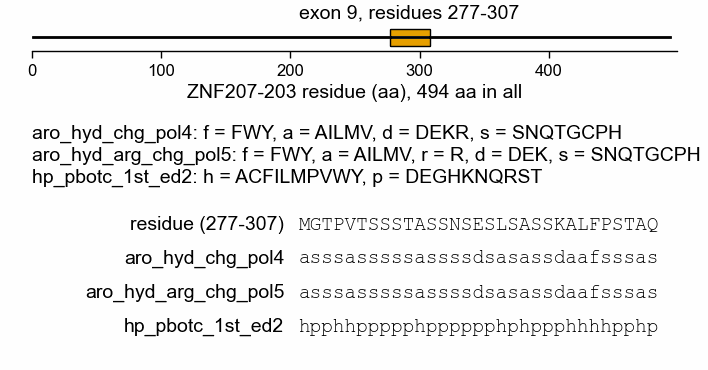

In [5]:
# ZNF207-203 as a line with exon 9 as a box, and the exon's residues in each alphabet searched.
# Axes are placed by hand: constrained layout collapses an axis that holds only text.
fig = plt.figure(figsize=(pf.ONE_COLUMN_MM * pf.MM, 50 * pf.MM), layout=None)
ax_protein = fig.add_axes([0.04, 0.80, 0.92, 0.07])
ax_seq = fig.add_axes([0.0, 0.0, 1.0, 0.62])
L = len(hero_protein)
ax_protein.plot([1, L], [0, 0], color="black", lw=1)
ax_protein.add_patch(
    plt.Rectangle(
        (HERO_FIRST, -0.5),
        HERO_LAST - HERO_FIRST + 1,
        1.0,
        facecolor=pf.OKABE_ITO["orange"],
        edgecolor="black",
        lw=0.5,
    )
)
ax_protein.text(
    (HERO_FIRST + HERO_LAST) / 2,
    0.9,
    f"exon 9, residues {HERO_FIRST}-{HERO_LAST}",
    ha="center",
    va="bottom",
)
ax_protein.set_xlim(0, L + 5)
ax_protein.set_ylim(-0.8, 0.8)
ax_protein.set_yticks([])
ax_protein.spines["left"].set_visible(False)
ax_protein.set_xlabel(f"{HERO_ISOFORM} residue (aa), {L} aa in all")

ax_seq.set_axis_off()
ax_seq.set_xlim(0, 1)
ax_seq.set_ylim(0, 1)
key_lines = [
    "aro_hyd_chg_pol4: f = FWY, a = AILMV, d = DEKR, s = SNQTGCPH",
    "aro_hyd_arg_chg_pol5: f = FWY, a = AILMV, r = R, d = DEK, s = SNQTGCPH",
    "hp_pbotc_1st_ed2: h = ACFILMPVWY, p = DEGHKNQRST",
]
for i, line in enumerate(key_lines):
    ax_seq.text(0.04, 0.95 - i * 0.09, line, ha="left", va="center")
rows = [(f"residue ({HERO_FIRST}-{HERO_LAST})", HERO_RESIDUES)] + [
    (name, cu.encode(HERO_RESIDUES, LETTER_TABLES[name]))
    for name in ["aro_hyd_chg_pol4", "aro_hyd_arg_chg_pol5", "hp_pbotc_1st_ed2"]
]
for i, (label, text) in enumerate(rows):
    y = 0.58 - i * 0.14
    ax_seq.text(0.40, y, label, ha="right", va="center")
    ax_seq.text(0.42, y, text, ha="left", va="center", family="monospace")
save_figure(fig, FIGURES / "342_znf207_exon9_residues_by_alphabet_ensembl116")

## 1. The exon table, the outcome classes and the tune and test halves

The event table is notebook 341's (Slurm job 47934291; code a06fb04). It already holds the read
counts of every replicate, so this section does not run anything on Sherlock: it applies rule 1
to the table. Genes are split into halves first (rule 2), from the gene list alone.

Ψ is recomputed here from the replicate counts and checked against the table's own Ψ columns. An
exon "codes for" exon_nt / 3 residues, the number of codons it adds.

In [6]:
events = pl.read_parquet(EVENTS_PATH)
DONORS = ["209", "334", "336"]
REGIONS = ["GZ", "CP"]  # germinal zone (progenitors), cortical plate (neurons)
REPLICATES = ["1", "2", "3", "4"]
MIN_READS = 20
CHANGE = 0.10
NO_CHANGE = 0.05
MIN_AA = 10
MAX_AA = 150

# Rule 2: split genes before anything about the exons is computed.
genes = sorted(events["gene_id"].unique().to_list())
order = np.random.default_rng(SEED).permutation(len(genes))
tune_genes = {genes[i] for i in order[: len(genes) // 2]}
events = events.with_columns(
    pl.when(pl.col("gene_id").is_in(tune_genes))
    .then(pl.lit("tune"))
    .otherwise(pl.lit("test"))
    .alias("half")
)
print(
    f"{len(genes)} genes: {len(tune_genes)} tune, {len(genes) - len(tune_genes)} test (seed {SEED})"
)

# Rule 1: Psi per donor per region, reads summed over the four replicates.
psi_cols = []
for d in DONORS:
    for r in REGIONS:
        inc = pl.sum_horizontal([pl.col(f"inc_{d}_{rep}_{r}") for rep in REPLICATES])
        skip = pl.sum_horizontal([pl.col(f"skip_{d}_{rep}_{r}") for rep in REPLICATES])
        psi_cols += [
            (inc + skip).alias(f"depth_{r}_{d}"),
            (inc / (inc + skip)).alias(f"psi342_{r}_{d}"),
        ]
events = events.with_columns(psi_cols).with_columns(
    [
        (pl.col(f"psi342_CP_{d}") - pl.col(f"psi342_GZ_{d}")).alias(f"dpsi_{d}")
        for d in DONORS
    ]
)
for d in DONORS:
    for r in REGIONS:
        both = events.filter(pl.col(f"psi_{r}_{d}").is_not_null())
        assert (both[f"psi342_{r}_{d}"] - both[f"psi_{r}_{d}"]).abs().max() < 1e-12, (
            r,
            d,
        )
        assert (both[f"depth_{r}_{d}"] == both[f"reads_{r}_{d}"]).all(), (r, d)
print(
    "Psi and read depth recomputed from the replicate counts equal the table's columns."
)

dpsi = [pl.col(f"dpsi_{d}") for d in DONORS]
events = events.with_columns(
    (pl.col("exon_nt") // 3).alias("exon_codons"),
    pl.min_horizontal(dpsi).alias("dpsi_min"),
    pl.max_horizontal(dpsi).alias("dpsi_max"),
    pl.all_horizontal(
        [pl.col(f"depth_{r}_{d}") >= MIN_READS for d in DONORS for r in REGIONS]
    ).alias("depth_ok"),
)
events = events.with_columns(
    pl.when(pl.col("dpsi_min") > CHANGE)
    .then(pl.lit("included more in neurons"))
    .when(pl.col("dpsi_max") < -CHANGE)
    .then(pl.lit("skipped more in neurons"))
    .when((pl.col("dpsi_min") > -NO_CHANGE) & (pl.col("dpsi_max") < NO_CHANGE))
    .then(pl.lit("unchanged"))
    .otherwise(pl.lit("left out"))
    .alias("outcome")
)

8890 genes: 4445 tune, 4445 test (seed 342)
Psi and read depth recomputed from the replicate counts equal the table's columns.


In [7]:
# The funnel: each step keeps the events that passed every step above it.
steps = [
    ("one-exon events in set A", pl.lit(True)),
    ("exon inside the including ORF", pl.col("exon_in_orf")),
    ("exon keeps the frame", pl.col("frame_preserving")),
    ("proteins differ only by the exon", pl.col("orf_otherwise_identical")),
    (
        f"exon adds {MIN_AA}-{MAX_AA} residues",
        pl.col("exon_codons").is_between(MIN_AA, MAX_AA),
    ),
    (f"at least {MIN_READS} reads per donor and region", pl.col("depth_ok")),
]
keep = pl.lit(True)
funnel_rows = []
for label, cond in steps:
    keep = keep & cond.fill_null(False)
    sub = events.filter(keep)
    funnel_rows.append(
        {"step": label, "events": sub.height, "genes": sub["gene_id"].n_unique()}
    )
exons = events.filter(keep)
funnel = pl.DataFrame(funnel_rows)
funnel = funnel.with_columns(
    (pl.col("events").shift(1) - pl.col("events")).alias("removed at this step")
)
print(funnel)

OUTCOMES = [
    "included more in neurons",
    "skipped more in neurons",
    "unchanged",
    "left out",
]
class_counts = (
    exons.group_by("outcome", "half")
    .agg(pl.len().alias("exons"), pl.col("gene_id").n_unique().alias("genes"))
    .pivot(on="half", index="outcome", values=["exons", "genes"])
    .with_columns(
        pl.col("outcome")
        .replace_strict({o: i for i, o in enumerate(OUTCOMES)})
        .alias("_o")
    )
    .sort("_o")
    .drop("_o")
    .select("outcome", "exons_tune", "exons_test", "genes_tune", "genes_test")
)
class_counts = class_counts.with_columns(
    (pl.col("exons_tune") + pl.col("exons_test")).alias("exons_total")
)
print(class_counts)
for outcome in OUTCOMES[:2]:
    n_tune = class_counts.filter(pl.col("outcome") == outcome)["exons_tune"].item()
    if n_tune < 100:
        print(
            f"POWER: '{outcome}' has {n_tune} exons on the tune half, under the 100 rule 4 asks for."
        )

shape: (6, 4)
┌─────────────────────────────────┬────────┬───────┬──────────────────────┐
│ step                            ┆ events ┆ genes ┆ removed at this step │
│ ---                             ┆ ---    ┆ ---   ┆ ---                  │
│ str                             ┆ i64    ┆ i64   ┆ i64                  │
╞═════════════════════════════════╪════════╪═══════╪══════════════════════╡
│ one-exon events in set A        ┆ 30548  ┆ 8890  ┆ null                 │
│ exon inside the including ORF   ┆ 14742  ┆ 6470  ┆ 15806                │
│ exon keeps the frame            ┆ 7500   ┆ 4155  ┆ 7242                 │
│ proteins differ only by the ex… ┆ 7062   ┆ 3939  ┆ 438                  │
│ exon adds 10-150 residues       ┆ 6572   ┆ 3791  ┆ 490                  │
│ at least 20 reads per donor an… ┆ 4513   ┆ 2781  ┆ 2059                 │
└─────────────────────────────────┴────────┴───────┴──────────────────────┘
shape: (4, 6)
┌──────────────────────────┬────────────┬────────────┬──────

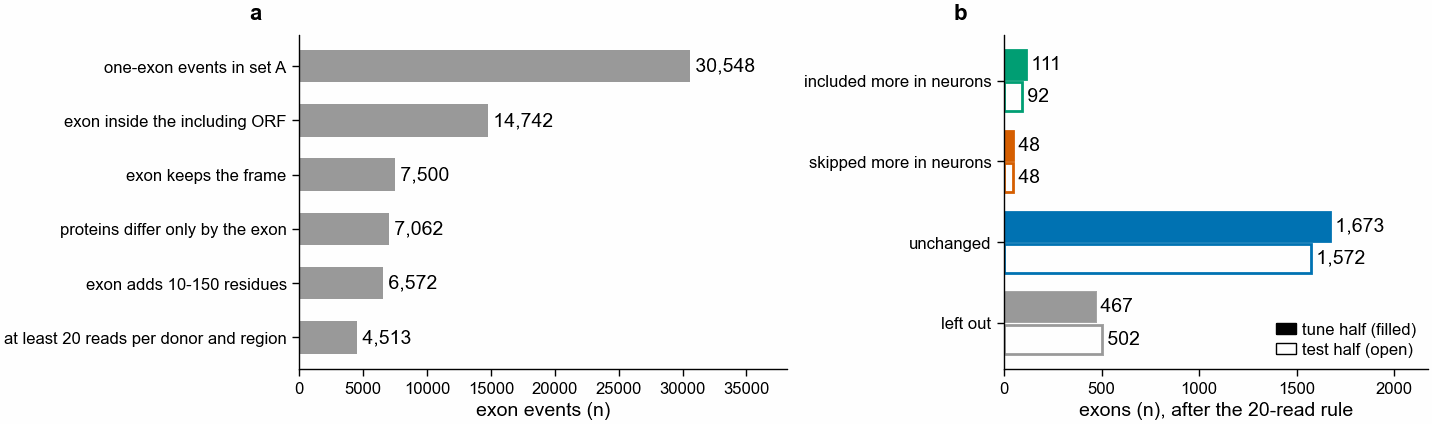

In [8]:
# a: the funnel; b: exons per outcome class and half.
COLOURS = {
    "included more in neurons": pf.OKABE_ITO["bluish_green"],
    "skipped more in neurons": pf.OKABE_ITO["vermillion"],
    "unchanged": pf.OKABE_ITO["blue"],
    "left out": pf.GREY,
}
fig, (ax_a, ax_b) = pf.figure(pf.TWO_COLUMN_MM, 55, ncols=2, width_ratios=[1.15, 1])
y = np.arange(funnel.height)[::-1]
ax_a.barh(y, funnel["events"], color=pf.GREY, height=0.6)
for yi, n in zip(y, funnel["events"]):
    ax_a.text(n, yi, f" {n:,}", va="center", ha="left")
ax_a.set_yticks(y, funnel["step"])
ax_a.set_xlabel("exon events (n)")
ax_a.set_xlim(0, funnel["events"].max() * 1.25)

yb = np.arange(len(OUTCOMES))[::-1]
offset = 0.2
for half, dy, fill in [("tune", offset, True), ("test", -offset, False)]:
    values = class_counts[f"exons_{half}"].to_list()
    colours = [COLOURS[o] for o in class_counts["outcome"]]
    ax_b.barh(
        yb + dy,
        values,
        height=0.36,
        color=colours if fill else "white",
        edgecolor=colours,
        lw=1,
    )
    for yi, n in zip(yb + dy, values):
        ax_b.text(n, yi, f" {n:,}", va="center", ha="left")
ax_b.set_yticks(yb, class_counts["outcome"])
ax_b.set_xlabel(f"exons (n), after the {MIN_READS}-read rule")
ax_b.set_xlim(0, class_counts["exons_tune"].max() * 1.3)
from matplotlib.patches import Patch

ax_b.legend(
    handles=[
        Patch(facecolor="black", edgecolor="black", label="tune half (filled)"),
        Patch(facecolor="white", edgecolor="black", label="test half (open)"),
    ],
    loc="lower right",
    frameon=False,
)
pf.panel_label(ax_a, "a")
pf.panel_label(ax_b, "b")
save_figure(fig, FIGURES / "342_setA_exon_funnel_and_classes_patowary2024")

shape: (4, 4)
┌──────────────────────────┬──────┬──────────────────────┬─────────────────────┐
│ outcome                  ┆ len  ┆ median smallest dPsi ┆ median largest dPsi │
│ ---                      ┆ ---  ┆ ---                  ┆ ---                 │
│ str                      ┆ u32  ┆ f64                  ┆ f64                 │
╞══════════════════════════╪══════╪══════════════════════╪═════════════════════╡
│ included more in neurons ┆ 203  ┆ 0.233                ┆ 0.362               │
│ left out                 ┆ 969  ┆ -0.058               ┆ 0.051               │
│ skipped more in neurons  ┆ 96   ┆ -0.254               ┆ -0.165              │
│ unchanged                ┆ 3245 ┆ -0.005               ┆ 0.005               │
└──────────────────────────┴──────┴──────────────────────┴─────────────────────┘


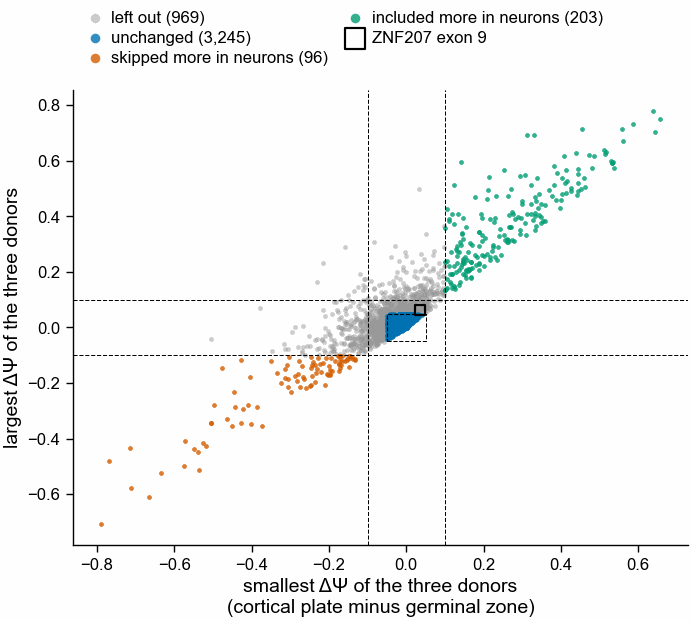

In [9]:
# Each exon by its smallest and largest change in Psi across the three donors. The rule's three
# classes are the regions inside the dashed lines. ZNF207 exon 9 is the black square.
hero = events.filter(
    (pl.col("gene_name") == HERO_GENE) & (pl.col("exon_residues") == HERO_RESIDUES)
)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 80)
for outcome in [
    "left out",
    "unchanged",
    "skipped more in neurons",
    "included more in neurons",
]:
    sub = exons.filter(pl.col("outcome") == outcome)
    ax.scatter(
        sub["dpsi_min"],
        sub["dpsi_max"],
        s=3,
        color=COLOURS[outcome],
        lw=0,
        alpha=0.5 if outcome == "left out" else 0.8,
        label=f"{outcome} ({sub.height:,})",
        rasterized=True,
    )
ax.scatter(
    hero["dpsi_min"],
    hero["dpsi_max"],
    s=14,
    marker="s",
    facecolor="none",
    edgecolor="black",
    lw=0.8,
    label="ZNF207 exon 9",
    zorder=5,
)
for v in (CHANGE, -CHANGE):
    ax.axvline(v, color="black", lw=0.4, ls="--")
    ax.axhline(v, color="black", lw=0.4, ls="--")
ax.plot(
    [-NO_CHANGE, NO_CHANGE, NO_CHANGE, -NO_CHANGE, -NO_CHANGE],
    [-NO_CHANGE, -NO_CHANGE, NO_CHANGE, NO_CHANGE, -NO_CHANGE],
    color="black",
    lw=0.4,
    ls="--",
)
ax.set_xlabel("smallest ΔΨ of the three donors\n(cortical plate minus germinal zone)")
ax.set_ylabel("largest ΔΨ of the three donors")
ax.legend(
    loc="upper left", bbox_to_anchor=(0, 1.2), ncol=2, frameon=False, markerscale=2
)
save_figure(fig, FIGURES / "342_setA_delta_psi_min_max_by_class_patowary2024")
print(
    exons.group_by("outcome")
    .agg(
        pl.len(),
        pl.col("dpsi_min").median().round(3).alias("median smallest dPsi"),
        pl.col("dpsi_max").median().round(3).alias("median largest dPsi"),
    )
    .sort("outcome")
)

In [10]:
# ZNF207 exon 9 under rule 1.
cols = [
    "gene_name",
    "including_isoform",
    "skipping_isoform",
    "exon_first_residue",
    "exon_last_residue",
    "half",
    *[f"psi342_{r}_{d}" for d in DONORS for r in REGIONS],
    *[f"dpsi_{d}" for d in DONORS],
    "outcome",
]
print(
    hero.select(cols)
    .with_columns(pl.col(pl.Float64).round(3))
    .transpose(include_header=True, column_names=["value"])
)

shape: (16, 2)
┌────────────────────┬─────────────────────┐
│ column             ┆ value               │
│ ---                ┆ ---                 │
│ str                ┆ str                 │
╞════════════════════╪═════════════════════╡
│ gene_name          ┆ ZNF207              │
│ including_isoform  ┆ ENST00000394670.8_1 │
│ skipping_isoform   ┆ ENST00000394673.6_3 │
│ exon_first_residue ┆ 277                 │
│ exon_last_residue  ┆ 307                 │
│ half               ┆ tune                │
│ psi342_GZ_209      ┆ 0.951               │
│ psi342_CP_209      ┆ 0.987               │
│ psi342_GZ_334      ┆ 0.91                │
│ psi342_CP_334      ┆ 0.973               │
│ psi342_GZ_336      ┆ 0.914               │
│ psi342_CP_336      ┆ 0.973               │
│ dpsi_209           ┆ 0.036               │
│ dpsi_334           ┆ 0.063               │
│ dpsi_336           ┆ 0.059               │
│ outcome            ┆ left out            │
└────────────────────┴──────────────────

### Three events checked by hand

ZNF207 exon 9, and in the tune half the "included more in neurons" and the "skipped more in
neurons" exon with the most reads. For each: the exon's lines in `Bulk.gtf` for both isoforms, the
genome sequence of the exon from Ensembl's GRCh37 server translated in the frame that gives the
table's residues, and the two proteins at the join.

In [11]:
import json
import re
import urllib.request

DATA_342 = REPO / "data" / "342_exon_function"
DATA_342.mkdir(parents=True, exist_ok=True)
CODON = {
    a + b + c: aa
    for (a, b, c), aa in zip(
        [(x, y, z) for x in "TCAG" for y in "TCAG" for z in "TCAG"],
        "FFLLSSSSYY**CC*WLLLLPPPPHHQQRRRRIIIMTTTTNNKKSSRRVVVVAAAADDEEGGGG",
    )
}


def grch37_sequence(chrom, start, end, strand):
    # Genome sequence, 1-based inclusive, on the exon's strand, from Ensembl's GRCh37 REST
    # server; cached under data/342_exon_function/.
    s = 1 if strand == "+" else -1
    path = DATA_342 / f"ensembl_grch37_{chrom}_{start}_{end}_{s}.txt"
    if not path.exists():
        url = (
            f"https://grch37.rest.ensembl.org/sequence/region/human/"
            f"{chrom.removeprefix('chr')}:{start}..{end}:{s}?content-type=text/plain"
        )
        with urllib.request.urlopen(url, timeout=60) as response:
            text = response.read().decode().strip()
        assert re.fullmatch("[ACGTN]+", text), text[:200]
        path.write_text(text + "\n")
    return path.read_text().strip()


best = {
    o: exons.filter((pl.col("outcome") == o) & (pl.col("half") == "tune"))
    .sort(
        pl.col("reads_including_total") + pl.col("reads_skipping_total"),
        descending=True,
    )
    .head(1)
    for o in OUTCOMES[:2]
}
checks = pl.concat([hero, *best.values()])
wanted = set(checks["including_isoform"]) | set(checks["skipping_isoform"])
gtf_exons = {t: [] for t in wanted}
with open(DRYAD / "Bulk.gtf") as fh:
    for line in fh:
        f = line.split("\t", 8)
        if len(f) > 8 and f[2] == "exon":
            t = re.search(r'transcript_id "([^"]+)"', f[8]).group(1)
            if t in gtf_exons:
                gtf_exons[t].append((int(f[3]), int(f[4])))

for row in checks.iter_rows(named=True):
    start, end = row["exon_start"], row["exon_end"]
    inc_exons, skip_exons = sorted(gtf_exons[row["including_isoform"]]), sorted(
        gtf_exons[row["skipping_isoform"]]
    )
    print(
        f"{row['gene_name']} ({row['outcome']}, {row['half']} half), {row['chrom']}:{start:,}-{end:,} "
        f"({row['strand']} strand, GRCh37), {row['exon_nt']} nt"
    )
    print(
        f"  including isoform {row['including_isoform']}: exon in Bulk.gtf: {(start, end) in inc_exons}"
    )
    joined = any(
        a[1] == row["upstream_exon_end"] and b[0] == row["downstream_exon_start"]
        for a, b in zip(skip_exons, skip_exons[1:])
    )
    print(
        f"  skipping isoform {row['skipping_isoform']}: exon in Bulk.gtf: {(start, end) in skip_exons}; "
        f"joins {row['upstream_exon_end']:,} straight to {row['downstream_exon_start']:,}: {joined}"
    )
    nt = grch37_sequence(row["chrom"], start, end, row["strand"])
    residues = row["exon_residues"]
    phase0 = len(residues) == row["exon_nt"] // 3
    frames = {
        f: "".join(CODON.get(nt[i : i + 3], "X") for i in range(f, len(nt) - 2, 3))
        for f in range(3)
    }
    inner = residues if phase0 else residues[1:-1]
    hit = [f for f, p in frames.items() if inner in p]
    print(
        f"  exon starts in phase {'0' if phase0 else '1 or 2'}; genome translation matches in frame {hit}"
    )
    print(f"  genome, {len(nt)} nt:     {nt}")
    print(f"  translated, frame {hit[0]}:  {frames[hit[0]]}")
    print(f"  table's exon residues: {residues}")
    first, last = row["exon_first_residue"], row["exon_last_residue"]
    print(
        f"  including protein, residues {first - 5}-{last + 5}:  "
        f"{row['protein_including'][first - 6 : first - 1].lower()}{residues}{row['protein_including'][last : last + 5].lower()}"
    )
    print(
        f"  skipping protein, residues {first - 5}-{first + 4}:     "
        f"{row['protein_skipping'][first - 6 : first + 4]}"
    )
    print(
        f"  Psi GZ/CP by donor: "
        + ", ".join(
            f"{d} {row[f'psi342_GZ_{d}']:.2f}/{row[f'psi342_CP_{d}']:.2f}"
            for d in DONORS
        )
        + "\n"
    )

ZNF207 (left out, tune half), chr17:30,693,684-30,693,776 (+ strand, GRCh37), 93 nt
  including isoform ENST00000394670.8_1: exon in Bulk.gtf: True
  skipping isoform ENST00000394673.6_3: exon in Bulk.gtf: False; joins 30,692,506 straight to 30,694,791: True
  exon starts in phase 0; genome translation matches in frame [0]
  genome, 93 nt:     ATGGGGACACCTGTCACAAGCTCAAGTACAGCTTCATCCAATTCAGAAAGTCTGTCTGCATCTTCTAAAGCTCTGTTTCCTAGCACAGCACAA
  translated, frame 0:  MGTPVTSSSTASSNSESLSASSKALFPSTAQ
  table's exon residues: MGTPVTSSSTASSNSESLSASSKALFPSTAQ
  including protein, residues 272-312:  psagqMGTPVTSSSTASSNSESLSASSKALFPSTAQaqaav
  skipping protein, residues 272-281:     PSAGQAQAAV
  Psi GZ/CP by donor: 209 0.95/0.99, 334 0.91/0.97, 336 0.91/0.97

GTF2I (included more in neurons, tune half), chr7:74,133,198-74,133,260 (+ strand, GRCh37), 63 nt
  including isoform ENST00000573035.5_1: exon in Bulk.gtf: True
  skipping isoform ENST00000621734.4_2: exon in Bulk.gtf: False; joins 74,131,270 s

In [12]:
# Write the exon table for Stops 2-4: one row per event that passed the funnel, with 20 residues of
# flank on each side from the including protein.
FLANK = 20
exon_table = (
    exons.with_columns(
        pl.struct("protein_including", "exon_first_residue")
        .map_elements(
            lambda r: r["protein_including"][
                max(0, r["exon_first_residue"] - 1 - FLANK) : r["exon_first_residue"]
                - 1
            ],
            return_dtype=pl.String,
        )
        .alias("flank_before"),
        pl.struct("protein_including", "exon_last_residue")
        .map_elements(
            lambda r: r["protein_including"][
                r["exon_last_residue"] : r["exon_last_residue"] + FLANK
            ],
            return_dtype=pl.String,
        )
        .alias("flank_after"),
        (pl.col("exon_residues").str.len_chars() == pl.col("exon_codons")).alias(
            "starts_in_phase_0"
        ),
        pl.lit("GRCh37").alias("genome_build"),
    )
    .select(
        "gene_id",
        "gene_name",
        "including_isoform",
        "skipping_isoform",
        "genome_build",
        "chrom",
        "strand",
        "exon_start",
        "exon_end",
        "exon_nt",
        "starts_in_phase_0",
        "exon_first_residue",
        "exon_last_residue",
        "exon_residues",
        "flank_before",
        "flank_after",
        *[f"depth_{r}_{d}" for d in DONORS for r in REGIONS],
        *[f"psi342_{r}_{d}" for d in DONORS for r in REGIONS],
        *[f"dpsi_{d}" for d in DONORS],
        "outcome",
        "half",
    )
    .rename({f"psi342_{r}_{d}": f"psi_{r}_{d}" for d in DONORS for r in REGIONS})
)
out = TABLES / "342_setA_exon_table_patowary2024_grch37.tsv"
exon_table.write_csv(out, separator="\t")
print(f"{exon_table.height} rows -> {out.relative_to(REPO)} (md5 {md5(out)})")
print(
    "exons per outcome in the written table:",
    dict(exon_table["outcome"].value_counts(sort=True).iter_rows()),
)

4513 rows -> tables/342/342_setA_exon_table_patowary2024_grch37.tsv (md5 52607bb853c05d0c25978b9d395a16a5)
exons per outcome in the written table: {'unchanged': 3245, 'left out': 969, 'included more in neurons': 203, 'skipped more in neurons': 96}


### What Stop 1 shows

* Of 30_548 one-exon events in 8_890 genes, 4_513 exons in 2_781 genes pass every filter. The
  largest losses are exons outside the ORF (15_806) and exons that shift the frame (7_242). The
  20-read rule removes 2_059 of the 6_572 exons left before it.
* Under rule 1: 203 exons are included more in neurons (111 tune, 92 test), 96 are skipped more
  in neurons (48 tune, 48 test), 3_245 are unchanged (1_673 tune, 1_572 test), and 969 are left out.
* The "skipped more in neurons" class has 48 exons on the tune half, under the 100 that rule 4
  asks for. Its test can still be run, but a gain of 0.02 is unlikely to be resolved; the
  "included more in neurons" comparison (111 tune exons) is the one with the power.
* ZNF207 exon 9 is left out: its ΔΨ is 0.036, 0.063 and 0.059 in the three donors, above 0 in all
  three but under 0.10, and above 0.05 in two.
* The three hand-checked exons (ZNF207, GTF2I, HNRNPM) are in the including isoform's exons in
  `Bulk.gtf` and absent from the skipping isoform, which joins the two neighbouring exons. Their
  genome sequence (Ensembl GRCh37) translates to the table's residues, and the skipping protein is
  the including one without them.

Olga saw these counts on 2026-10-16 and said to go ahead with Stop 2.

## 2. Labels of kinds 1 to 3, and the positive control

`scripts/342_exon_labels_kinds_1_3.py` computes every label below for each of the 4_513 exons,
and the same for its context: the 20 residues before the exon plus the 20 after it, from the
including protein. No k-mer search is used.

* **Kind 1.** hmmscan (HMMER 3.4) against Pfam-A 38.2 with `--domE 0.001`, on the whole including
  protein. Domain extent is the envelope (the stretch HMMER assigns to the domain). Values: the
  fraction of exon residues inside any domain; the family covering the most exon residues; whether
  the exon starts or ends inside a domain.
* **Kind 2.** ELM class regexes (the classes file, not the instances), matched on the whole
  protein. A match counts for the exon if it overlaps the exon and lies within 5 residues of it.
  UniProt MOD_RES sites (modified residues) of the gene's reviewed human entry, placed on the
  including protein where the 11 residues around the site occur exactly once.
* **Kind 3.** IUPred long mean (run on the whole protein, averaged over the residues); κ;
  Ω_aro (only above 10% aromatic residues, else missing); NCPR (net charge per residue) and FCR
  (fraction of charged residues), both from localCIDER 0.1.21; the share of each
  `aro_hyd_chg_pol4` class; the fraction of residues SEG marks as low complexity (segmasker,
  BLAST+ 2.16.0, defaults, run on the whole protein); length.

Ω_aro uses notebook 341's `condensate_exon_utils.omega_aro`, which needs more than 10% aromatic
residues, as Martin et al. 2020 write. The prompt for this notebook said "at least 10%". The two
differ only for an exon with exactly 10% aromatic residues.

shape: (10, 2)
┌──────────────────────────────┬─────────────────────────────────┐
│ input or tool                ┆ version or checksum             │
│ ---                          ┆ ---                             │
│ str                          ┆ str                             │
╞══════════════════════════════╪═════════════════════════════════╡
│ exon table md5               ┆ 52607bb853c05d0c25978b9d395a16… │
│ including proteins FASTA md5 ┆ 2bdbb3dcdcea004e5f43c10f5e2ba8… │
│ Pfam-A.hmm md5               ┆ 589ccc8370eaf079022db0dbb25c8a… │
│ hmmscan                      ┆ # HMMER 3.4 (Aug 2023); http:/… │
│ segmasker BLAST+             ┆ blastp: 2.16.0+                 │
│ elm_date                     ┆ 2026-10-15 21:34:02.818438      │
│ elm_md5                      ┆ c35f375de2ce92f0286932ba07ada0… │
│ elm_classes                  ┆ 353                             │
│ UniProt                      ┆ https://rest.uniprot.org/unipr… │
│ labels md5                   ┆ 7fe6f6f3d442a1

MOD_RES sites in the matched UniProt entries: 14231; placed on an including protein: 12578 (counted once per gene)


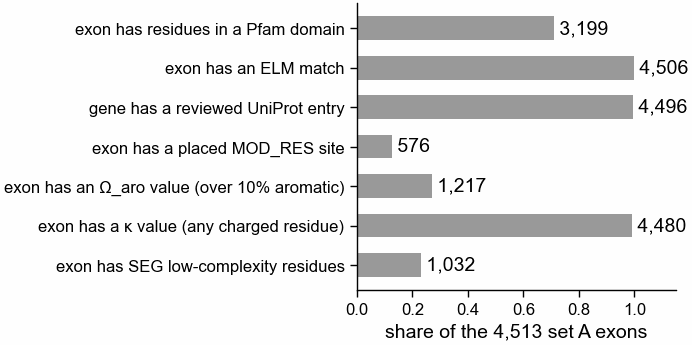

In [13]:
LABELS_PATH = TABLES / "342_setA_exon_labels_kinds1to3.tsv"
labels = pl.read_csv(LABELS_PATH, separator="\t", infer_schema_length=None)
provenance = pl.read_csv(
    TABLES / "342_setA_exon_labels_kinds1to3.provenance.tsv",
    separator="\t",
    has_header=False,
    new_columns=["input or tool", "version or checksum"],
)
assert provenance.filter(pl.col("input or tool") == "labels md5")[
    "version or checksum"
].item() == md5(LABELS_PATH)
assert labels.height == exon_table.height
print(provenance)

coverage = pl.DataFrame(
    {
        "label": [
            "exon has residues in a Pfam domain",
            "exon has an ELM match",
            "gene has a reviewed UniProt entry",
            "exon has a placed MOD_RES site",
            "exon has an Ω_aro value (over 10% aromatic)",
            "exon has a κ value (any charged residue)",
            "exon has SEG low-complexity residues",
        ],
        "exons": [
            labels.filter(pl.col("k1_domain_fraction_exon") > 0).height,
            labels.filter(pl.col("k2_elm_count_exon") > 0).height,
            labels.filter(pl.col("k2_mod_res_gene_has_entry")).height,
            labels.filter(pl.col("k2_mod_res_count_exon") > 0).height,
            labels.filter(pl.col("k3_omega_aro_exon").is_not_nan()).height,
            labels.filter(pl.col("k3_kappa_exon").is_not_nan()).height,
            labels.filter(pl.col("k3_seg_fraction_exon") > 0).height,
        ],
    }
).with_columns((pl.col("exons") / labels.height).round(3).alias("share of 4_513"))
print(coverage)
sites = labels.unique("gene_name").select(
    pl.col("k2_mod_res_sites_seen").sum(), pl.col("k2_mod_res_sites_placed").sum()
)
# Share of the 4_513 exons that carry each label.
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 45)
y = np.arange(coverage.height)[::-1]
ax.barh(y, coverage["share of 4_513"], color=pf.GREY, height=0.6)
for yi, share, n in zip(y, coverage["share of 4_513"], coverage["exons"]):
    ax.text(share, yi, f" {n:,}", va="center", ha="left")
ax.set_yticks(y, coverage["label"])
ax.set_xlim(0, 1.15)
ax.set_xlabel("share of the 4,513 set A exons")
save_figure(fig, FIGURES / "342_setA_label_coverage_kinds1to3_patowary2024")
print(
    f"MOD_RES sites in the matched UniProt entries: {sites.item(0, 0)}; placed on an including protein: "
    f"{sites.item(0, 1)} (counted once per gene)"
)

In [14]:
# ZNF207 exon 9's labels.
hero_labels = labels.filter(
    (pl.col("gene_name") == HERO_GENE) & (pl.col("exon_first_residue") == HERO_FIRST)
)
print(
    hero_labels.select(pl.exclude("event_id")).transpose(
        include_header=True, column_names=["value"]
    )
)

shape: (40, 2)
┌─────────────────────────────────┬─────────────────────────────────┐
│ column                          ┆ value                           │
│ ---                             ┆ ---                             │
│ str                             ┆ str                             │
╞═════════════════════════════════╪═════════════════════════════════╡
│ gene_name                       ┆ ZNF207                          │
│ outcome                         ┆ left out                        │
│ half                            ┆ tune                            │
│ exon_first_residue              ┆ 277                             │
│ exon_last_residue               ┆ 307                             │
│ k1_domain_fraction_exon         ┆ 0.0                             │
│ k1_domain_fraction_context      ┆ 0.0                             │
│ k1_starts_inside_domain         ┆ false                           │
│ k1_ends_inside_domain           ┆ false                           │
│ k1_

### The positive control (rule 3, prediction P1)

On the tune half: the mean IUPred score of exons in the two changed classes together, minus that
of unchanged exons. The 95% interval comes from 10_000 resamples of genes (all exons of a drawn gene
come along). The control holds if the whole interval is above 0.

In [15]:
N_BOOT = 10_000
CHANGED = ["included more in neurons", "skipped more in neurons"]


def gene_bootstrap_mean_difference(
    df, value, group_a, group_b, n_boot=N_BOOT, seed=SEED
):
    # Mean of `value` in group_a minus group_b, and its gene-resampled bootstrap values.
    # group_a / group_b are boolean expressions; each gene is drawn with replacement and
    # brings all its exons.
    per_gene = (
        df.group_by("gene_name")
        .agg(
            pl.col(value).filter(group_a).sum().alias("sum_a"),
            group_a.sum().alias("n_a"),
            pl.col(value).filter(group_b).sum().alias("sum_b"),
            group_b.sum().alias("n_b"),
        )
        .sort("gene_name")
    )
    arr = per_gene.select("sum_a", "n_a", "sum_b", "n_b").to_numpy().astype(float)
    observed = arr[:, 0].sum() / arr[:, 1].sum() - arr[:, 2].sum() / arr[:, 3].sum()
    rng = np.random.default_rng(seed)
    draws = rng.multinomial(
        len(per_gene), np.full(len(per_gene), 1 / len(per_gene)), size=n_boot
    )
    totals = draws @ arr
    boot = totals[:, 0] / totals[:, 1] - totals[:, 2] / totals[:, 3]
    return observed, boot, len(per_gene)


tune = labels.filter((pl.col("half") == "tune") & (pl.col("outcome") != "left out"))
is_changed = pl.col("outcome").is_in(CHANGED)
diff, boot, n_genes = gene_bootstrap_mean_difference(
    tune, "k3_iupred_mean_exon", is_changed, ~is_changed
)
lo, hi = np.percentile(boot, [2.5, 97.5])
P1_HOLDS = lo > 0
print(
    tune.group_by("outcome")
    .agg(
        pl.len().alias("exons"),
        pl.col("gene_name").n_unique().alias("genes"),
        pl.col("k3_iupred_mean_exon").mean().round(3).alias("mean IUPred"),
        pl.col("k3_iupred_mean_exon").median().round(3).alias("median IUPred"),
    )
    .sort("outcome")
)
print(
    f"\nchanged minus unchanged, mean IUPred: {diff:+.3f} (95% interval {lo:+.3f} to {hi:+.3f}; "
    f"{N_BOOT:_} resamples of {n_genes} tune genes)"
)
print("P1 / rule 3:", "HOLDS" if P1_HOLDS else "FAILS: the notebook stops here")
for o in CHANGED:
    d, b, _ = gene_bootstrap_mean_difference(
        tune,
        "k3_iupred_mean_exon",
        pl.col("outcome") == o,
        pl.col("outcome") == "unchanged",
    )
    print(
        f"  {o} minus unchanged: {d:+.3f} ({np.percentile(b, 2.5):+.3f} to {np.percentile(b, 97.5):+.3f})"
    )

shape: (3, 5)
┌──────────────────────────┬───────┬───────┬─────────────┬───────────────┐
│ outcome                  ┆ exons ┆ genes ┆ mean IUPred ┆ median IUPred │
│ ---                      ┆ ---   ┆ ---   ┆ ---         ┆ ---           │
│ str                      ┆ u32   ┆ u32   ┆ f64         ┆ f64           │
╞══════════════════════════╪═══════╪═══════╪═════════════╪═══════════════╡
│ included more in neurons ┆ 111   ┆ 92    ┆ 0.496       ┆ 0.502         │
│ skipped more in neurons  ┆ 48    ┆ 45    ┆ 0.484       ┆ 0.448         │
│ unchanged                ┆ 1673  ┆ 1101  ┆ 0.31        ┆ 0.26          │
└──────────────────────────┴───────┴───────┴─────────────┴───────────────┘

changed minus unchanged, mean IUPred: +0.182 (95% interval +0.144 to +0.219; 10_000 resamples of 1181 tune genes)
P1 / rule 3: HOLDS


  included more in neurons minus unchanged: +0.186 (+0.141 to +0.228)


  skipped more in neurons minus unchanged: +0.174 (+0.101 to +0.246)


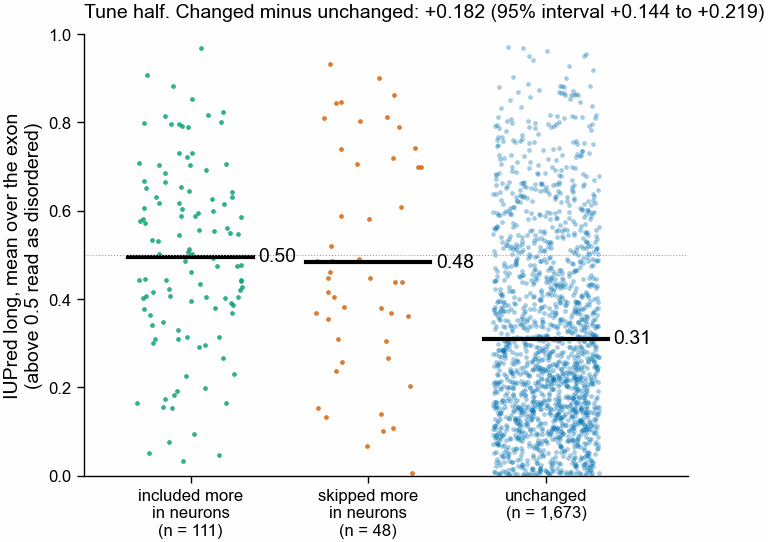

In [16]:
# IUPred mean per exon, by outcome class, tune half. Each dot is one exon; the black bar is the class mean.
ORDER = ["included more in neurons", "skipped more in neurons", "unchanged"]
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 70)
rng_jitter = np.random.default_rng(SEED)
for i, outcome in enumerate(ORDER):
    vals = tune.filter(pl.col("outcome") == outcome)["k3_iupred_mean_exon"].to_numpy()
    x = i + rng_jitter.uniform(-0.3, 0.3, vals.size)
    ax.scatter(
        x,
        vals,
        s=3,
        lw=0,
        color=COLOURS[outcome],
        alpha=0.35 if outcome == "unchanged" else 0.8,
        rasterized=True,
    )
    ax.plot([i - 0.35, i + 0.35], [vals.mean()] * 2, color="black", lw=1.5)
    ax.text(i + 0.38, vals.mean(), f"{vals.mean():.2f}", va="center", ha="left")
ax.axhline(0.5, color=pf.GREY, lw=0.4, ls=":")
ax.set_xticks(
    range(len(ORDER)),
    [
        f"{o.replace(' in ', chr(10) + 'in ')}\n(n = {tune.filter(pl.col('outcome') == o).height:,})"
        for o in ORDER
    ],
)
ax.set_ylabel("IUPred long, mean over the exon\n(above 0.5 read as disordered)")
ax.set_ylim(0, 1)
ax.set_xlim(-0.6, len(ORDER) - 0.2)
ax.set_title(
    f"Tune half. Changed minus unchanged: {diff:+.3f} (95% interval {lo:+.3f} to {hi:+.3f})",
    loc="left",
)
save_figure(fig, FIGURES / "342_setA_iupred_by_outcome_tune_half_patowary2024")

### Alphabet check for Stop 3

The share of each `aro_hyd_chg_pol4` class in every exon of the tune half. If the median aromatic
share is below 5%, `aro_hyd_chg_pol4` k-mers on most exons are almost all polar and other
hydrophobic letters, so a search in that alphabet alone would see little of the aromatic residues.
The four settings of Stop 3 stay as listed whatever this shows; no alphabet is added for this
notebook.

{'aromatic': 0.067, 'other_hydrophobic': 0.294, 'charged': 0.222, 'polar': 0.394}
median aromatic share below 5%: False


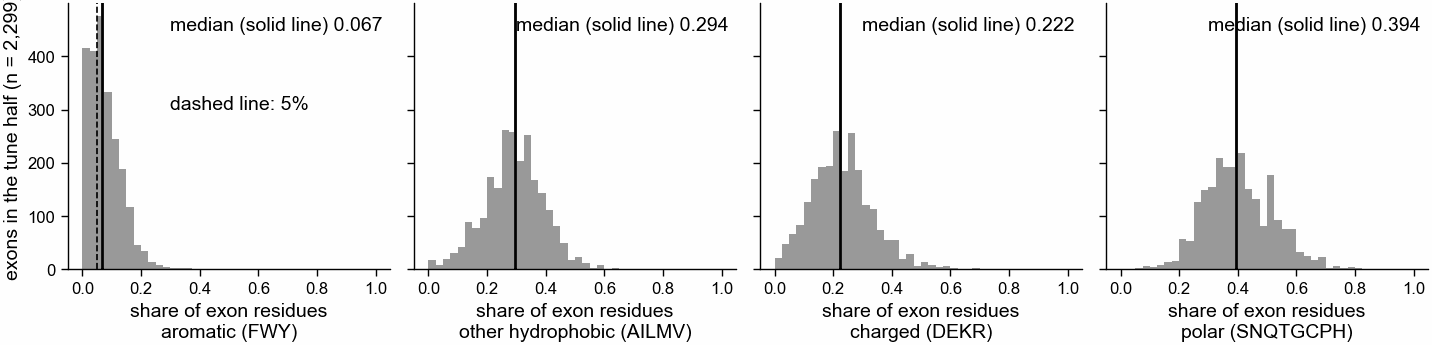

In [17]:
POL4_CLASSES = [
    ("aromatic", "FWY"),
    ("other_hydrophobic", "AILMV"),
    ("charged", "DEKR"),
    ("polar", "SNQTGCPH"),
]
tune_all = labels.filter(pl.col("half") == "tune")
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 45, ncols=4, sharey=True)
medians = {}
for ax, (name, residues) in zip(axs, POL4_CLASSES):
    vals = tune_all[f"k3_pol4_frac_{name}_exon"].to_numpy()
    medians[name] = float(np.median(vals))
    ax.hist(vals, bins=np.linspace(0, 1, 41), color=pf.GREY)
    ax.axvline(medians[name], color="black", lw=1)
    ax.text(
        0.3,
        ax.get_ylim()[1] * 0.95,
        f"median (solid line) {medians[name]:.3f}",
        ha="left",
        va="top",
    )
    ax.set_xlabel(f"share of exon residues\n{name.replace('_', ' ')} ({residues})")
axs[0].axvline(0.05, color="black", lw=0.6, ls="--")
axs[0].text(0.3, axs[0].get_ylim()[1] * 0.6, "dashed line: 5%", ha="left")
axs[0].set_ylabel(f"exons in the tune half (n = {tune_all.height:,})")
save_figure(
    fig, FIGURES / "342_setA_aro_hyd_chg_pol4_class_shares_tune_half_patowary2024"
)
print({k: round(v, 3) for k, v in medians.items()})
ARO_MEDIAN_BELOW_5 = medians["aromatic"] < 0.05
print("median aromatic share below 5%:", ARO_MEDIAN_BELOW_5)

In [18]:
# Numbers quoted in the Stop 2 summary below.
elm_per_residue = (labels["k2_elm_count_exon"] / labels["k3_length_aa_exon"]).median()
print(f"median ELM class matches per exon residue: {elm_per_residue:.2f}")
import gzip

with gzip.open(
    TABLES / "342_setA_including_proteins.pfam38.2.domE0.001.domtbl.gz", "rt"
) as fh:
    domain_rows = [line.split()[3] for line in fh if not line.startswith("#")]
print(
    f"Pfam domains at i-E <= 0.001: {len(domain_rows)} on {len(set(domain_rows))} of "
    f"{labels.height} exons' {exon_table['including_isoform'].n_unique()} including proteins"
)

median ELM class matches per exon residue: 0.43
Pfam domains at i-E <= 0.001: 39922 on 3599 of 4513 exons' 3623 including proteins


### What Stop 2 shows

* **P1 holds.** On the tune half, exons that neurons include or skip more than progenitors have a
  mean IUPred score 0.182 higher than unchanged exons (95% interval +0.144 to +0.219, 10_000
  resamples of 1_181 genes). Both changed classes clear 0 on their own: +0.186 for included more,
  +0.174 for skipped more. This matches Buljan et al. 2012: exons whose use changes between cell
  types are more disordered. The exon table and the outcome rule pass the check, so the notebook
  goes on.
* **Label coverage.** 71% of exons have residues in a Pfam domain, 13% have a placed UniProt
  modified residue, 27% have more than 10% aromatic residues (so an Ω_aro value), and 23% have
  residues SEG marks as low complexity.
* **ELM class matches are nearly everywhere** (99.8% of exons; a median of 0.43 matches per exon
  residue), because a class regex is short and loose. The ELM count is close to a length measure.
  It stays in model 3 as rule 4 lists it, next to length.
* **ZNF207 exon 9** has no Pfam domain, no UniProt modified residue (UniProt lists none for
  O43670), IUPred mean 0.78 and 65% of its residues marked low complexity by SEG.
* **Alphabet check.** The median aromatic share of tune-half exons is 6.7%, above 5%. The four
  kmerseek settings of Stop 3 stay as listed.

Stop 3 runs kmerseek on Sherlock (section 3).

## 3. Kind 4: the queries used for kmerseek

`scripts/342_make_queries.py` writes one query per exon: the exon with 20 residues of flank on each
side, from the including protein. Each query has one decoy, a dipeptide-shuffled copy
(`nextflow-runs/shared/decoys.py`, PR 138; seed 342) named `DECOY_<event id>`. A decoy keeps the
query's residues, its first and last residue and its count of every residue pair, so it has the
same composition but no real match. All 4_513 exons are searched, in both halves and all classes.

At this stage the search had not yet run. The search runs on Sherlock with `scripts/342_stop3_submit.sh`, which submits one
job per step of `scripts/342_stop3.sbatch`:

1. Build kmerseek from the tag `nb342-kmerseek-9ce5865` of seanome/kmerseek: `main` 00395d7 plus
   PR 146 (the two new alphabets), PR 144 (`--ka-r-database`) and PR 152 (index entries keyed by
   their sequence, the port of PR 141's fix to `main`). All 341 kmerseek tests pass on that commit.
2. Rebuild PR 114's 10-residue-window decoys of both indexes with its script and seed. Each decoy
   file must match the md5 PR 114 published, so the indexes hold the same decoys.
3. Build 8 indexes: the regions index and the whole-protein index for each of the 4 settings. The
   whole-protein index is built only for its E-value fit.
4. Search the regions index with the queries in 10 chunks per setting, using the whole-protein
   index's fit. Keep regions with E ≤ 10.
5. Score with `scripts/342_kind4_features.py`: the own-gene filter, the decoy-matched cutoff of
   each setting on the tune half, and the kind 4 features per exon.

Each job's memory and time come from the measured peaks in PR 114's Sherlock traces (table below).
The two new alphabets have no history; they borrow polarity4 k11's, the closest measured alphabet.

342_setA_exon_queries_with_decoys.fasta: 9026 records (4513 exons, 4513 decoys), md5 fb388f253f1026d4e9a77acf37e86870
shape: (1, 3)
┌───────────────┬────────┬─────────┐
│ shortest (aa) ┆ median ┆ longest │
│ ---           ┆ ---    ┆ ---     │
│ i64           ┆ f64    ┆ i64     │
╞═══════════════╪════════╪═════════╡
│ 33            ┆ 75.0   ┆ 191     │
└───────────────┴────────┴─────────┘


shape: (15, 8)
┌────────┬──────────────────────┬─────┬─────────┬────────┬───────┬──────────────────┬───────────────┐
│ step   ┆ alphabet             ┆ k   ┆ index   ┆ mem_gb ┆ hours ┆ measured_peak_gb ┆ measured_time │
│ ---    ┆ ---                  ┆ --- ┆ ---     ┆ ---    ┆ ---   ┆ ---              ┆ ---           │
│ str    ┆ str                  ┆ str ┆ str     ┆ i64    ┆ i64   ┆ str              ┆ str           │
╞════════╪══════════════════════╪═════╪═════════╪════════╪═══════╪══════════════════╪═══════════════╡
│ build  ┆ -                    ┆ -   ┆ -       ┆ 32     ┆ 1     ┆ 9.7              ┆ 4m52s         │
│ decoys ┆ -                    ┆ -   ┆ -       ┆ 24     ┆ 1     ┆ -                ┆ -             │
│ index  ┆ aro_hyd_chg_pol4     ┆ 11  ┆ regions ┆ 110    ┆ 2     ┆ 80.1             ┆ 20m25s        │
│ index  ┆ aro_hyd_arg_chg_pol5 ┆ 9   ┆ regions ┆ 110    ┆ 2     ┆ 80.1             ┆ 20m25s        │
│ index  ┆ hp_pbotc_1st_ed2     ┆ 21  ┆ regions ┆ 48     ┆ 1     ┆ 

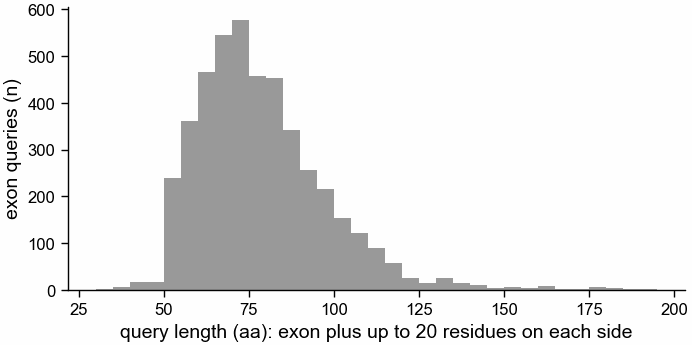

In [19]:
queries = pl.read_csv(TABLES / "342_setA_exon_queries.tsv", separator="\t")
fasta_path = TABLES / "342_setA_exon_queries_with_decoys.fasta"
assert (TABLES / "342_setA_exon_queries_with_decoys.fasta.md5").read_text().split()[
    0
] == md5(fasta_path)
n_records = sum(line.startswith(">") for line in open(fasta_path))
print(
    f"{fasta_path.name}: {n_records} records ({queries.height} exons, {n_records - queries.height} decoys), "
    f"md5 {md5(fasta_path)}"
)
print(
    queries.select(
        pl.col("query_length").min().alias("shortest (aa)"),
        pl.col("query_length").median().alias("median"),
        pl.col("query_length").max().alias("longest"),
    )
)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 45)
ax.hist(queries["query_length"], bins=np.arange(30, 200, 5), color=pf.GREY)
ax.set_xlabel("query length (aa): exon plus up to 20 residues on each side")
ax.set_ylabel("exon queries (n)")
save_figure(fig, FIGURES / "342_setA_exon_query_lengths_patowary2024")
print(
    pl.read_csv(
        TABLES / "342_stop3_resources.tsv", separator="\t", comment_prefix="#"
    ).select(
        "step",
        "alphabet",
        "k",
        "index",
        "mem_gb",
        "hours",
        "measured_peak_gb",
        "measured_time",
    )
)

## 3b. Kind 4 from three of the four settings

Stop 3 scored three of its four kmerseek settings: aro_hyd_chg_pol4 k = 11, aro_hyd_arg_chg_pol5
k = 9 and hp_pbotc_1st_ed2 k = 21. **protein20 k = 5 is left out** (Olga, 2026-10-21). With
kmerseek tag `nb342-kmerseek-9ce5865`, all three protein20 index builds compute a closed-form match
probability of 0.000, the chance that two random residues match (the other alphabets get 0.28 to
0.50; 20 amino acids should give about 0.06). With no match probability there is no λ, so no
E-value fit (refused with 500 and with 2_500 fit queries, jobs 48247325 and 48685828) and every E
is inf (a test search with a K given, job 48803101, returned 148_972 calls, all with E = inf). This
is a kmerseek bug; Stop 0's fourth setting waits for its fix.

This section reads the three-setting score: job 48804096, `scripts/342_kind4_features.py` at
commit fa52f117, copied to `tables/342/score_3settings/` and checked against the md5 sums in its
`provenance.tsv`. That scorer drops calls whose E is not a finite number: over 99.9% of the
574_553_721 rows the searches wrote had E = inf, and the search step's E ≤ 10 filter had let them
through (awk reads "inf" as 0). 113_106 calls have a finite E.

It shows each setting's decoy-matched cutoff, predictions P2 and P3, the own-gene filter and the
strongest hit in each setting. It does not compare outcome classes on the test half; that is rule
4, in Stop 4 below.

Words used below:

* **Call**: a region kmerseek reports at E ≤ 10 whose query stretch overlaps at least one exon
  residue, on a real Swiss-Prot entry (not a decoy entry of the index) of another gene.
* **Decoy query**: a dipeptide-shuffled copy of an exon query (same residues and residue pairs,
  no real match).
* **Decoy-matched cutoff**: per setting, the E below which at most 5% of the 2_299 tune-half decoy
  queries have a call. A **hit** is a call below that cutoff.

In [20]:
import math

SCORE3 = TABLES / "score_3settings"
score_prov = pl.read_csv(SCORE3 / "provenance.tsv", separator="\t", comment_prefix="#")
for f, want in score_prov.iter_rows():
    assert md5(SCORE3 / f) == want, f"{f} changed since it was copied from Sherlock"
cutoffs3 = pl.read_csv(SCORE3 / "cutoffs.tsv", separator="\t")
k4 = pl.read_csv(
    SCORE3 / "kind4_features.tsv", separator="\t", infer_schema_length=None
)
own3 = pl.read_csv(SCORE3 / "own_gene_hits.tsv", separator="\t")
best3 = pl.read_csv(SCORE3 / "best_hits.tsv", separator="\t", infer_schema_length=None)
assert k4.height == queries.height
#: The three settings scored so far, in the order of the settings table, with one colour each.
SETTINGS3 = {
    "aro_hyd_chg_pol4_k11_s1": ("aro_hyd_chg_pol4, k = 11", pf.OKABE_ITO["blue"]),
    "aro_hyd_arg_chg_pol5_k9_s1": (
        "aro_hyd_arg_chg_pol5, k = 9",
        pf.OKABE_ITO["vermillion"],
    ),
    "hp_pbotc_1st_ed2_k21_s1": (
        "hp_pbotc_1st_ed2, k = 21",
        pf.OKABE_ITO["bluish_green"],
    ),
}
assert set(SETTINGS3) == set(cutoffs3["setting"])
TOOL_LINE = (
    "kmerseek: set A exon queries (exon plus 20 residues each side) against the regions index "
    "(Swiss-Prot 2026_03 annotated regions, no mammals; PR 114). protein20 k = 5 left out: no E-values in this kmerseek build."
)
# If the E-values were right, a decoy would have at least one call below E with probability 1 - exp(-E),
# so 5% of decoys would fall below E = ln(1 / 0.95) = 0.051. The ratio says how far each setting is off.
E_AT_5PCT = math.log(1 / 0.95)
print(
    cutoffs3.with_columns(
        (pl.col("tune_decoys_with_a_call") / pl.col("tune_decoy_queries"))
        .round(3)
        .alias("share of tune decoys with any call at E <= 10"),
        pl.when(pl.col("cutoff_evalue") < E_AT_5PCT)
        .then(
            pl.format(
                "{} times too small", (E_AT_5PCT / pl.col("cutoff_evalue")).round(1)
            )
        )
        .otherwise(
            pl.format(
                "{} times too large", (pl.col("cutoff_evalue") / E_AT_5PCT).round(1)
            )
        )
        .alias(f"E-values, against the {E_AT_5PCT:.3f} a right E would give"),
    )
)

shape: (3, 7)
┌────────────────────────┬────────────────────┬────────────────────────┬───────────────┬───────────────────────┬───────────────────────┬───────────────────────┐
│ setting                ┆ tune_decoy_queries ┆ tune_decoys_with_a_cal ┆ cutoff_evalue ┆ tune_decoys_below_cut ┆ share of tune decoys  ┆ E-values, against the │
│ ---                    ┆ ---                ┆ l                      ┆ ---           ┆ off                   ┆ with any …            ┆ 0.051 a …             │
│ str                    ┆ i64                ┆ ---                    ┆ f64           ┆ ---                   ┆ ---                   ┆ ---                   │
│                        ┆                    ┆ i64                    ┆               ┆ i64                   ┆ f64                   ┆ str                   │
╞════════════════════════╪════════════════════╪════════════════════════╪═══════════════╪═══════════════════════╪═══════════════════════╪═══════════════════════╡
│ aro_hyd_arg_chg_po

The cutoffs show how far each setting's E-values are from right. If they were right, a decoy
would have a call below E with probability 1 − e^(−E), and 5% of decoys would fall below
E = 0.051. aro_hyd_arg_chg_pol5 k = 9 reaches that 5% at E = 0.0074, so its E-values are about 7
times too small: 1_424 of its 2_299 tune-half decoys (62%) have a call at E ≤ 10.
aro_hyd_chg_pol4 k = 11 (cutoff 1.04) and hp_pbotc_1st_ed2 k = 21 (cutoff 5.8) err the other way,
about 20 and 113 times too large. The decoy-matched cutoff puts the three settings on the same
footing: 5% of decoys pass in each.

The figure shows, per setting, the share of the 4_513 exons whose best call is at or below each E,
with the cutoff (dashed) and E = 1 (grey band) marked.

shape: (3, 5)
┌─────────────────────────────┬───────────────────────────────┬──────────────────┬─────────────┬────────────────────────────────┐
│ setting                     ┆ exons with any call (E <= 10) ┆ below the cutoff ┆ below E = 1 ┆ below E = 0.000001 (left edge) │
│ ---                         ┆ ---                           ┆ ---              ┆ ---         ┆ ---                            │
│ str                         ┆ i64                           ┆ i64              ┆ i64         ┆ i64                            │
╞═════════════════════════════╪═══════════════════════════════╪══════════════════╪═════════════╪════════════════════════════════╡
│ aro_hyd_chg_pol4, k = 11    ┆ 1470                          ┆ 606              ┆ 601         ┆ 69                             │
│ aro_hyd_arg_chg_pol5, k = 9 ┆ 3042                          ┆ 439              ┆ 1487        ┆ 92                             │
│ hp_pbotc_1st_ed2, k = 21    ┆ 911                           ┆ 603         

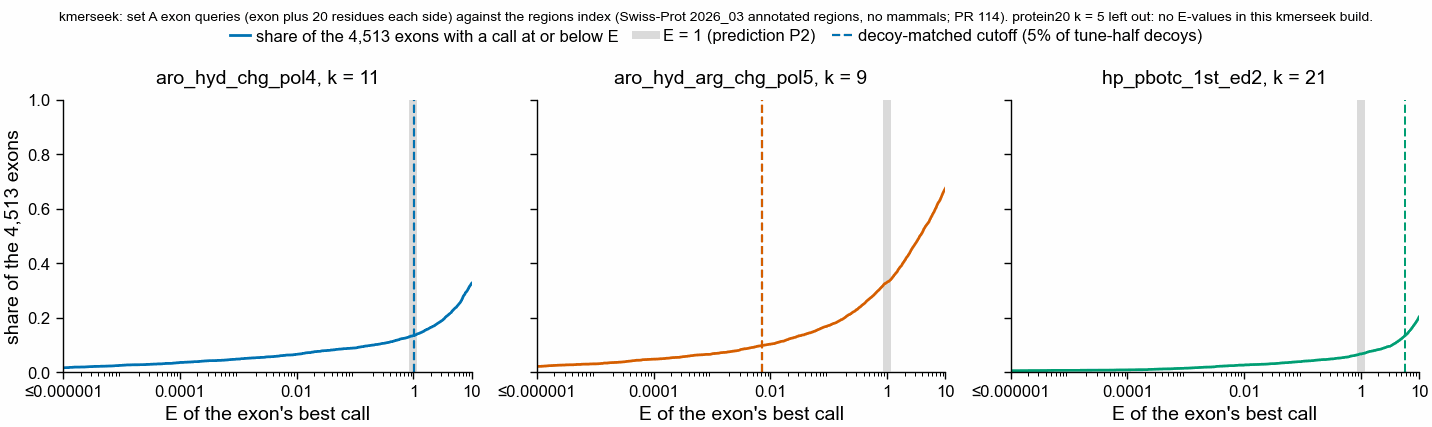

In [21]:
# Per exon and setting, the smallest E of a call on another gene's real Swiss-Prot entry, as the share
# of all 4_513 exons whose best call is at or below each E. Exons with no call are never counted.
E_MIN, E_MAX = 1e-6, 10.0
grid = np.logspace(np.log10(E_MIN), np.log10(E_MAX), 400)
rows = []
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 55, ncols=3, sharey=True)
for ax, (setting, (label, colour)) in zip(axs, SETTINGS3.items()):
    e = k4[f"k4_best_e_{setting}"].drop_nulls().to_numpy()
    share = np.searchsorted(np.sort(e), grid, side="right") / k4.height
    cut = cutoffs3.filter(pl.col("setting") == setting)["cutoff_evalue"].item()
    ax.plot(
        grid,
        share,
        color=colour,
        lw=1,
        label="share of the 4,513 exons with a call at or below E",
    )
    # E = 1 first, wide and pale, so a cutoff near 1 (aro_hyd_chg_pol4: 1.04) stays visible on top of it.
    ax.axvline(
        1.0, color=pf.GREY, lw=3, alpha=0.35, label="E = 1 (prediction P2)", zorder=1
    )
    ax.axvline(
        cut,
        color=colour,
        lw=0.8,
        ls="--",
        label="decoy-matched cutoff (5% of tune-half decoys)",
        zorder=2,
    )
    ax.set_xscale("log")
    ax.set_xlim(E_MIN, E_MAX)
    ticks = [1e-6, 1e-4, 1e-2, 1, 10]
    ax.set_xticks(ticks, ["≤0.000001", "0.0001", "0.01", "1", "10"])
    ax.set_title(label)
    ax.set_xlabel("E of the exon's best call")
    rows.append(
        {
            "setting": label,
            "exons with any call (E <= 10)": len(e),
            "below the cutoff": int((e < cut).sum()),
            "below E = 1": int((e < 1).sum()),
            "below E = 0.000001 (left edge)": int((e <= E_MIN).sum()),
        }
    )
axs[0].set_ylabel("share of the 4,513 exons")
axs[0].set_ylim(0, 1)
pf.shared_legend(fig, ncol=3, title=TOOL_LINE, title_fontsize=5)
save_figure(
    fig, FIGURES / "342_setA_kind4_3settings_best_evalue_by_exon_swissprot_regions"
)
print(pl.DataFrame(rows))

In aro_hyd_arg_chg_pol5, 1_487 exons have a call at E < 1 but only 439 pass its cutoff. In
aro_hyd_chg_pol4 the two counts nearly meet (601 and 606). In hp_pbotc_1st_ed2, 298 exons have a
call at E < 1 and 603 pass its cutoff at E = 5.8. So a count at E < 1, as P2 is written, mixes
settings whose E-values mean different things; a count at the cutoffs does not.

P2: 1661 of 4513 exons (36.8%) have a call at E < 1; P2 predicted under 30%.
1063 of 4513 exons (23.6%) have a hit at their setting's decoy-matched cutoff.
shape: (2, 4)
┌──────┬───────┬───────────────────┬───────────────┐
│ half ┆ exons ┆ hit at the cutoff ┆ call at E < 1 │
│ ---  ┆ ---   ┆ ---               ┆ ---           │
│ str  ┆ u32   ┆ u32               ┆ u32           │
╞══════╪═══════╪═══════════════════╪═══════════════╡
│ tune ┆ 2299  ┆ 547               ┆ 838           │
│ test ┆ 2214  ┆ 516               ┆ 823           │
└──────┴───────┴───────────────────┴───────────────┘
shape: (6, 3)
┌─────────────────────────────┬──────┬────────────────────────────────┐
│ setting                     ┆ half ┆ share with a hit at the cutoff │
│ ---                         ┆ ---  ┆ ---                            │
│ str                         ┆ str  ┆ f64                            │
╞═════════════════════════════╪══════╪════════════════════════════════╡
│ aro_hyd_chg_pol4, k = 11    ┆ 

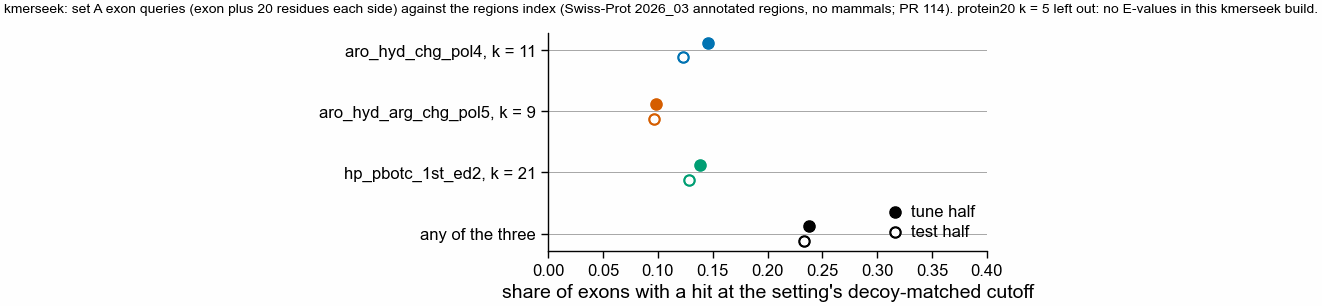

In [22]:
# P2: exons with a call at E < 1 in any setting (on another gene's real Swiss-Prot entry).
n_p2 = int(k4["k4_any_call_e_below_1"].sum())
n_hit = int(k4["k4_has_hit"].sum())
by_half = (
    k4.group_by("half")
    .agg(
        pl.len().alias("exons"),
        pl.col("k4_has_hit").sum().alias("hit at the cutoff"),
        pl.col("k4_any_call_e_below_1").sum().alias("call at E < 1"),
    )
    .sort("half", descending=True)
)
per_setting_hits = pl.DataFrame(
    [
        {
            "setting": SETTINGS3[s][0],
            "half": h,
            "share with a hit at the cutoff": k4.filter(pl.col("half") == h)
            .select(
                (
                    pl.col(f"k4_best_e_{s}")
                    < cutoffs3.filter(pl.col("setting") == s)["cutoff_evalue"].item()
                )
                .fill_null(False)
                .mean()
            )
            .item(),
        }
        for s in SETTINGS3
        for h in ["tune", "test"]
    ]
)
print(
    f"P2: {n_p2} of {k4.height} exons ({n_p2 / k4.height:.1%}) have a call at E < 1; P2 predicted under 30%."
)
print(
    f"{n_hit} of {k4.height} exons ({n_hit / k4.height:.1%}) have a hit at their setting's decoy-matched cutoff."
)
print(by_half)
print(per_setting_hits)
hit_exons = k4.filter(pl.col("k4_has_hit"))
print(
    hit_exons.group_by("k4_best_setting")
    .len()
    .sort("len", descending=True)
    .rename({"len": "exons whose best hit is from it"})
)
print(
    hit_exons["k4_n_settings_with_hit"]
    .value_counts()
    .sort("k4_n_settings_with_hit")
    .rename({"count": "exons"})
)
# Each setting's share of exons with a hit at its cutoff, by half (no outcome classes here).
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 40)
names = [v[0] for v in SETTINGS3.values()] + ["any of the three"]
y = np.arange(len(names))[::-1]
for half, marker_fill in [("tune", True), ("test", False)]:
    sub = k4.filter(pl.col("half") == half)
    vals = [
        per_setting_hits.filter((pl.col("setting") == n) & (pl.col("half") == half))[
            "share with a hit at the cutoff"
        ].item()
        for n in names[:-1]
    ] + [sub["k4_has_hit"].mean()]
    colours = [v[1] for v in SETTINGS3.values()] + ["black"]
    for yi, v, c in zip(y, vals, colours):
        ax.scatter(
            v,
            yi + (0.12 if half == "tune" else -0.12),
            s=14,
            color=c if marker_fill else "white",
            edgecolors=c,
            lw=0.8,
            label=f"{half} half" if yi == y[-1] else None,
            zorder=3,
        )
ax.set_yticks(y, names)
for yi in y:
    ax.axhline(yi, color=pf.GREY, lw=0.3, zorder=0)
ax.set_xlim(0, max(0.4, k4["k4_has_hit"].mean() * 1.2))
ax.set_xlabel("share of exons with a hit at the setting's decoy-matched cutoff")
ax.legend(loc="lower right", frameon=False)
fig.suptitle(TOOL_LINE, fontsize=5)
save_figure(
    fig, FIGURES / "342_setA_kind4_3settings_exons_with_a_hit_by_half_swissprot_regions"
)

**P2 fails.** 1_661 of 4_513 exons (36.8%) have a call at E < 1 in at least one setting; P2
predicted under 30%. Most of the excess is aro_hyd_arg_chg_pol5's E-values being too small.

At the decoy-matched cutoffs, 1_063 exons (23.6%) have a hit: 547 of 2_299 on the tune half and
516 of 2_214 on the test half. Each setting gives a hit to 10% to 15% of exons in each half. The
best hit comes from each setting about equally often (383, 350 and 330 exons), and 625 of the
1_063 exons have a hit in one setting only.

P3 asks whether the strength of a hit is mostly the kind 3 features in another form.

shape: (3, 3)
┌─────────────────────────────────┬───────┬──────────────┐
│ feature                         ┆ exons ┆ spearman_rho │
│ ---                             ┆ ---   ┆ ---          │
│ str                             ┆ i64   ┆ f64          │
╞═════════════════════════════════╪═══════╪══════════════╡
│ IUPred mean of the exon (0 ord… ┆ 1063  ┆ 0.002        │
│ share of A, I, L, M, V in the … ┆ 1063  ┆ -0.089       │
│ share of the exon SEG calls lo… ┆ 1063  ┆ -0.011       │
└─────────────────────────────────┴───────┴──────────────┘
P3: does not hold on three settings
Not a written test; outcome classes not used:
shape: (2, 3)
┌────────────┬───────┬─────────────────────────────────┐
│ k4_has_hit ┆ exons ┆ share with exon residues in a … │
│ ---        ┆ ---   ┆ ---                             │
│ bool       ┆ u32   ┆ f64                             │
╞════════════╪═══════╪═════════════════════════════════╡
│ true       ┆ 1063  ┆ 0.763                           │
│ false      ┆ 34

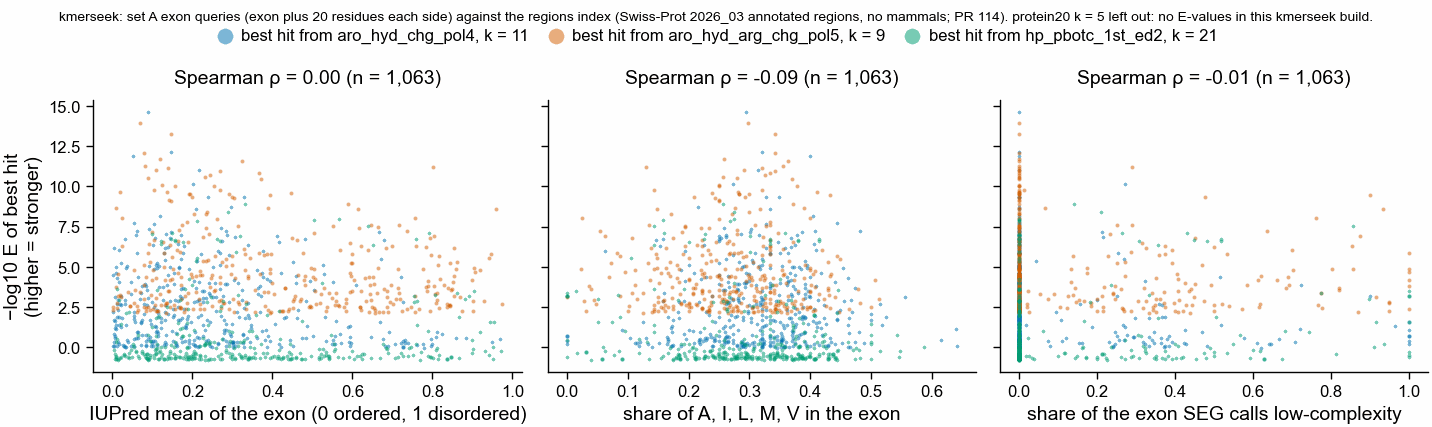

In [23]:
from scipy.stats import spearmanr

# P3: over exons with a hit at the cutoff, Spearman correlation between -log10(best E) and three
# kind 3 features of the exon. P3 holds if |rho| > 0.5 for at least one.
P3_FEATURES = {
    "k3_iupred_mean_exon": "IUPred mean of the exon (0 ordered, 1 disordered)",
    "k3_pol4_frac_other_hydrophobic_exon": "share of A, I, L, M, V in the exon",
    "k3_seg_fraction_exon": "share of the exon SEG calls low-complexity",
}
with_hit = k4.filter(pl.col("k4_has_hit")).join(
    labels.select("event_id", *P3_FEATURES), on="event_id"
)
assert with_hit.height == n_hit
p3 = []
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 55, ncols=3, sharey=True)
for ax, (col, label) in zip(axs, P3_FEATURES.items()):
    sub = with_hit.filter(pl.col(col).is_not_nan() & pl.col(col).is_not_null())
    rho, p = spearmanr(sub[col], sub["k4_neglog10_best_e"])
    p3.append(
        {"feature": label, "exons": sub.height, "spearman_rho": round(float(rho), 3)}
    )
    for setting, (name, colour) in SETTINGS3.items():
        part = sub.filter(pl.col("k4_best_setting") == setting)
        ax.scatter(
            part[col],
            part["k4_neglog10_best_e"],
            s=2,
            lw=0,
            color=colour,
            alpha=0.5,
            label=f"best hit from {name}",
        )
    ax.set_xlabel(label)
    ax.set_title(f"Spearman ρ = {rho:.2f} (n = {sub.height:,})")
axs[0].set_ylabel("−log10 E of best hit\n(higher = stronger)")
pf.shared_legend(fig, ncol=3, markerscale=4, title=TOOL_LINE, title_fontsize=5)
save_figure(
    fig, FIGURES / "342_setA_kind4_3settings_strength_vs_kind3_swissprot_regions"
)
p3 = pl.DataFrame(p3)
print(p3)
print(
    "P3:",
    "HOLDS" if (p3["spearman_rho"].abs() > 0.5).any() else "does not hold",
    "on three settings",
)
# Not one of the written tests: do exons with a hit lie in a Pfam domain (kind 1) more often than the rest?
pfam = (
    k4.join(labels.select("event_id", "k1_domain_fraction_exon"), on="event_id")
    .group_by("k4_has_hit")
    .agg(
        pl.len().alias("exons"),
        (pl.col("k1_domain_fraction_exon") > 0)
        .mean()
        .round(3)
        .alias("share with exon residues in a Pfam domain"),
    )
    .sort("k4_has_hit", descending=True)
)
print("Not a written test; outcome classes not used:")
print(pfam)

**P3 does not hold.** Over the 1_063 exons with a hit, the Spearman correlation between −log10 E
of the best hit and the exon's IUPred mean, AILMV share or SEG low-complexity share is 0.00,
−0.09 and −0.01. P3 asked for at least one above 0.5 in size. How strong an exon's hit is does
not follow its disorder, hydrophobic share or low complexity. Whether the hit adds to the kind 1
to 3 features in predicting splicing is the question Stop 4 tests.

One check that is not among the written tests, with no outcome classes: 76.3% of exons with a hit
have residues in a Pfam domain, against 69.2% of exons without a hit. Hits lean only a little
toward exons that kind 1 already labels.

The own-gene filter (Olga, 2026-10-16) removes calls to the query's own gene in other animals.

shape: (6, 6)
┌─────────────────────────────┬──────┬───────────────────────┬──────────────────┬──────────────────────────┬───────────────────┐
│ setting                     ┆ half ┆ calls_on_real_targets ┆ removed_own_gene ┆ exons_with_own_gene_call ┆ kept_similar_name │
│ ---                         ┆ ---  ┆ ---                   ┆ ---              ┆ ---                      ┆ ---               │
│ str                         ┆ str  ┆ i64                   ┆ i64              ┆ i64                      ┆ i64               │
╞═════════════════════════════╪══════╪═══════════════════════╪══════════════════╪══════════════════════════╪═══════════════════╡
│ aro_hyd_arg_chg_pol5, k = 9 ┆ test ┆ 14432                 ┆ 263              ┆ 153                      ┆ 39                │
│ aro_hyd_arg_chg_pol5, k = 9 ┆ tune ┆ 13000                 ┆ 303              ┆ 189                      ┆ 31                │
│ aro_hyd_chg_pol4, k = 11    ┆ test ┆ 3393                  ┆ 311              ┆ 1

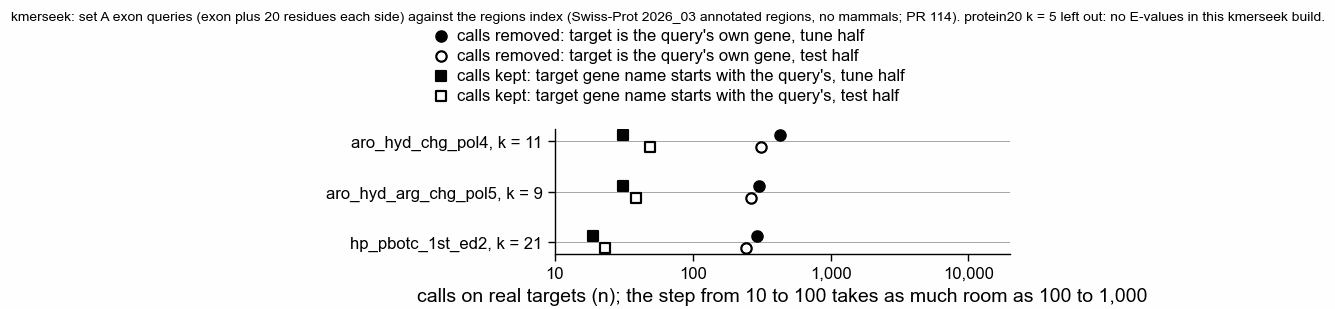

In [24]:
own_view = own3.with_columns(
    pl.col("setting").replace_strict({k: v[0] for k, v in SETTINGS3.items()})
)
print(own_view)
# Calls the own-gene filter removed, and kept calls to a target whose gene name starts with the query's.
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 40)
names = [v[0] for v in SETTINGS3.values()]
y = np.arange(len(names))[::-1]
for col, marker, lab in [
    ("removed_own_gene", "o", "calls removed: target is the query's own gene"),
    ("kept_similar_name", "s", "calls kept: target gene name starts with the query's"),
]:
    for half, fill in [("tune", True), ("test", False)]:
        sub = own_view.filter(pl.col("half") == half)
        vals = [sub.filter(pl.col("setting") == n)[col].item() for n in names]
        ax.scatter(
            vals,
            y + (0.12 if half == "tune" else -0.12),
            marker=marker,
            s=14,
            color="black" if fill else "white",
            edgecolors="black",
            lw=0.8,
            label=f"{lab}, {half} half",
            zorder=3,
        )
ax.set_yticks(y, names)
for yi in y:
    ax.axhline(yi, color=pf.GREY, lw=0.3, zorder=0)
ax.set_xscale("log")
ax.set_xticks([10, 100, 1_000, 10_000], ["10", "100", "1,000", "10,000"])
ax.set_xticks([], minor=True)
ax.set_xlim(10, 20_000)
ax.set_xlabel(
    "calls on real targets (n); the step from 10 to 100 takes as much room as 100 to 1,000"
)
pf.shared_legend(fig, ncol=1, title=TOOL_LINE, title_fontsize=5)
save_figure(fig, FIGURES / "342_setA_kind4_3settings_own_gene_calls_swissprot_regions")

The filter removed 245 to 431 calls per setting and half, from 150 to 247 exons, out of 1_621 to
14_432 calls on real targets. Calls kept to a target whose gene name starts with the query's
symbol (a paralog the filter does not catch) number 19 to 49.

The strongest hit in each setting on the tune half, with both residue strings:

In [25]:
# The tune-half exon with the smallest E at the cutoff in each setting, its query and target residues.
examples = (
    best3.filter(
        (pl.col("half") == "tune") & (pl.col("evalue") < pl.col("cutoff_evalue"))
    )
    .sort("evalue", "event_id")
    .group_by("setting", maintain_order=True)
    .first()
    .sort("setting")
)
for r in examples.iter_rows(named=True):
    print(
        f"{SETTINGS3[r['setting']][0]}: {r['gene_name']} exon {r['event_id']} ({r['outcome']}), E = {r['evalue']:.2g}"
    )
    print(f"  target {r['target']} (gene {r['target_gene_names']})")
    q, t = r["qseq"], r["tseq"]
    match = "".join("|" if a == b else " " for a, b in zip(q, t))
    print(f"  query  {r['qstart']:>4}-{r['qend']:<4} {q}")
    print(f"  {'':16} {match}")
    print(f"  target {r['tstart']:>4}-{r['tend']:<4} {t}")
    print(
        f"  {match.count('|')} of {min(len(q), len(t))} residues identical (no gaps; kmerseek regions are ungapped)"
    )

aro_hyd_arg_chg_pol5, k = 9: CSNK2A1 exon CSNK2A1_ENST00000646561.1_2_472898_473008 (unchanged), E = 1.1e-14
  target P15790|DOMAIN|Protein_kinase|40-363 (gene CKA1)
  query     1-77   GIMHRDVKPHNVMIDHEHRKLRLIDWGLAEFYHPGQEYNVRVASRYFKGPELLVDYQMYDYSLDMWSLGCMLASMIF
                   ||||||||||||||||   ||||||||||||||   ||||||||| |||||||||| ||||||| || | |||||||
  target  172-248  GIMHRDVKPHNVMIDHKNKKLRLIDWGLAEFYHVNMEYNVRVASRFFKGPELLVDYRMYDYSLDLWSFGTMLASMIF
  66 of 77 residues identical (no gaps; kmerseek regions are ungapped)
aro_hyd_chg_pol4, k = 11: PIP5K1A exon PIP5K1A_ENST00000349792.9_1_151205027_151205179 (unchanged), E = 2.5e-15
  target Q5ZJ58|DOMAIN|PIPK|25-395 (gene PIP5K1B)
  query     1-91   APVAFRYFRELFGIRPDDYLYSLCSEPLIELCSSGASGSLFYVSSDDEFIIKTVQHKEAEFLQKLLPGYYMNLNQNPRTLLPKFYGLYCVQ
                   || ||||||||||| ||||||| ||||||||   ||||||| | |||||||||||||||||||||||||||||||||||||||||||||||
  target   84-174  APLAFRYFRELFGIKPDDYLYSICSEPLIELSNPGASGSLFFVTSDDEFIIKTVQHKEAEFLQKLLPGY

### What the early look says

* With the three settings that have E-values, prediction P2 fails (36.8% of exons have a call at E < 1, against
  under 30% predicted) and P3 does not hold (|ρ| at most 0.09, against 0.5).
* 1_063 of 4_513 exons (23.6%) have a hit at the decoy-matched cutoffs, in nearly equal shares on
  the two halves.
* The three settings' E-values are off by different factors (about 7 times too small for
  aro_hyd_arg_chg_pol5 k = 9; about 20 and 113 times too large for aro_hyd_chg_pol4 k = 11 and
  hp_pbotc_1st_ed2 k = 21). The decoy-matched cutoffs, set on the tune half, correct for this.
* The strongest hit in each setting is on an annotated folded domain (a protein kinase domain, a
  PIPK domain, a fibronectin type III domain), with 66 of 77, 83 of 91 and 96 of 127 residues
  identical (76% to 91%).
* protein20 k = 5 has no E-values in this kmerseek build (match probability 0.000) and is left out.
* Stop 4 below runs rule 4 on these three settings.

## 4. Stop 4: the kill test (rule 4), on three kmerseek settings

Rule 4 as Stop 0 wrote it, with one change: kind 4 comes from the three settings that have
E-values. protein20 k = 5 is left out because this kmerseek build gives it no E-values (section 3b;
Olga, 2026-10-21).

* Two comparisons, each a logistic regression: "included more in neurons" against "unchanged", and
  "skipped more in neurons" against "unchanged".
* **Model 3**: the kind 1 to 3 columns of `342_setA_exon_labels_kinds1to3.tsv`, every number and
  0/1 column. The two text columns (Pfam family name, list of ELM classes) are left out, since they
  are not numbers.
* **Model 4**: model 3 plus kind 4: has a hit at the decoy-matched cutoff, −log10 E of the best hit
  (0 when there is no hit), the number of settings with a hit, and one 0/1 column per feature type of
  the best hit (the types seen on the tune half).
* A missing value is set to 0 and gets its own 0/1 column. Features are standardized; the L2
  penalty strength C is chosen from 13 values between 0.0001 and 100 by 5-fold cross-validation on
  the tune half, with folds split by gene.
* Each model is fitted on the tune half and scored once on the test half. AUROC is the chance that
  a random exon of the changed class scores higher than a random unchanged exon: 0.5 is no signal,
  higher is better.
* **PASS** if the whole 95% interval of the gain (model 4 minus model 3, 10_000 resamples of test
  genes) is at or above 0.02; **KILL** if it is all below 0.02; unclear otherwise.
* "Skipped more in neurons" has 48 exons on each half, under the 100 rule 4 asks for, so that
  comparison is unlikely to resolve a gain of 0.02 (section 1).

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

#: Rule 4's threshold on the AUROC gain, model 4 minus model 3.
MIN_GAIN = 0.02
N_FOLDS = 5
#: Columns of the kinds 1 to 3 table that are not features: names, positions, and two text columns
#: (the Pfam family name and the list of ELM classes), which are not numbers.
NOT_FEATURES = {
    "event_id",
    "gene_name",
    "outcome",
    "half",
    "exon_first_residue",
    "exon_last_residue",
    "k1_family",
    "k2_elm_classes_exon",
}
KIND123 = [c for c in labels.columns if c not in NOT_FEATURES]
FEATURE_TYPES = sorted(
    k4.filter((pl.col("half") == "tune") & pl.col("k4_has_hit"))[
        "k4_best_feature_type"
    ].unique()
)


def design(df, columns, missing_columns=None):
    # Booleans to 0/1; a missing or NaN value to 0 with its own 0/1 column (rule 4).
    out = []
    for c in columns:
        x = df[c].cast(pl.Float64)
        missing = x.is_null() | x.is_nan()
        add_indicator = (
            missing.any() if missing_columns is None else c in missing_columns
        )
        if add_indicator:
            out += [
                x.fill_nan(None).fill_null(0.0).alias(c),
                missing.cast(pl.Float64).alias(f"{c}_missing"),
            ]
        else:
            out.append(x.fill_nan(None).fill_null(0.0).alias(c))
    return pl.DataFrame(out)


data = labels.join(
    k4.select(
        "event_id",
        "k4_has_hit",
        "k4_neglog10_best_e",
        "k4_best_feature_type",
        "k4_n_settings_with_hit",
    ),
    on="event_id",
)
assert data.height == labels.height
data = data.with_columns(
    pl.col("k4_neglog10_best_e").fill_null(
        0.0
    ),  # no hit: 0, and k4_has_hit says it is missing
    *[
        (pl.col("k4_best_feature_type") == t)
        .fill_null(False)
        .alias(f"k4_best_type_{t}")
        for t in FEATURE_TYPES
    ],
)
KIND4 = ["k4_has_hit", "k4_neglog10_best_e", "k4_n_settings_with_hit"] + [
    f"k4_best_type_{t}" for t in FEATURE_TYPES
]
print(
    f"model 3: {len(KIND123)} kind 1 to 3 columns; model 4 adds {len(KIND4)} kind 4 columns: {KIND4}"
)

model 3: 33 kind 1 to 3 columns; model 4 adds 10 kind 4 columns: ['k4_has_hit', 'k4_neglog10_best_e', 'k4_n_settings_with_hit', 'k4_best_type_COILED', 'k4_best_type_COMPBIAS', 'k4_best_type_DOMAIN', 'k4_best_type_MOTIF', 'k4_best_type_REGION', 'k4_best_type_REPEAT', 'k4_best_type_TRANSMEM']


In [27]:
def auroc(y, score):
    # Mann-Whitney form: the chance a random positive outscores a random negative, ties count half.
    from scipy.stats import rankdata

    r = rankdata(score)
    n_pos = y.sum()
    n_neg = len(y) - n_pos
    return (r[y == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)


def fit_and_score(changed_class, columns):
    # Fit on the tune half (C by 5-fold cross-validation, folds split by gene), score the test half once.
    sub = data.filter(pl.col("outcome").is_in([changed_class, "unchanged"]))
    tune, test = sub.filter(pl.col("half") == "tune"), sub.filter(
        pl.col("half") == "test"
    )
    X_tune = design(tune, columns)
    X_test = design(
        test, columns, {c[:-8] for c in X_tune.columns if c.endswith("_missing")}
    ).select(
        [c for c in X_tune.columns]
    )  # same columns as the fit
    y_tune = (tune["outcome"] == changed_class).cast(pl.Int8).to_numpy()
    y_test = (test["outcome"] == changed_class).cast(pl.Int8).to_numpy()
    folds = list(
        GroupKFold(n_splits=N_FOLDS).split(
            X_tune, y_tune, groups=tune["gene_name"].to_numpy()
        )
    )
    model = GridSearchCV(
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
        {"logisticregression__C": np.logspace(-4, 2, 13)},
        cv=folds,
        scoring="roc_auc",
    )
    model.fit(X_tune.to_numpy(), y_tune)
    return {
        "score": model.predict_proba(X_test.to_numpy())[:, 1],
        "y": y_test,
        "genes": test["gene_name"].to_numpy(),
        "C": float(model.best_params_["logisticregression__C"]),
        "n_tune": (int(y_tune.sum()), int((1 - y_tune).sum())),
        "n_test": (int(y_test.sum()), int((1 - y_test).sum())),
        "columns": X_tune.columns,
    }


def gene_bootstrap_gain(m3, m4, n_boot=N_BOOT, seed=SEED):
    # Resample test genes with replacement; AUROC of both models on the same resampled exons.
    rng = np.random.default_rng(seed)
    genes = np.unique(m3["genes"])
    idx = {g: np.flatnonzero(m3["genes"] == g) for g in genes}
    gains = []
    for _ in range(n_boot):
        rows = np.concatenate(
            [idx[g] for g in rng.choice(genes, size=len(genes), replace=True)]
        )
        y = m3["y"][rows]
        if y.min() == y.max():
            continue
        gains.append(auroc(y, m4["score"][rows]) - auroc(y, m3["score"][rows]))
    return np.array(gains)


stop4 = []
predictions = []
for changed in ["included more in neurons", "skipped more in neurons"]:
    m3, m4 = fit_and_score(changed, KIND123), fit_and_score(changed, KIND123 + KIND4)
    assert (m3["y"] == m4["y"]).all() and (m3["genes"] == m4["genes"]).all()
    predictions.append(
        pl.DataFrame(
            {
                "comparison": changed,
                "gene": m3["genes"],
                "y": m3["y"],
                "model3_score": m3["score"],
                "model4_score": m4["score"],
            }
        )
    )
    a3, a4 = auroc(m3["y"], m3["score"]), auroc(m4["y"], m4["score"])
    gains = gene_bootstrap_gain(m3, m4)
    lo, hi = np.percentile(gains, [2.5, 97.5])
    verdict = "PASS" if lo >= MIN_GAIN else "KILL" if hi < MIN_GAIN else "unclear"
    row = {
        "comparison": f"{changed} vs unchanged",
        "tune exons (changed, unchanged)": str(m3["n_tune"]),
        "test exons (changed, unchanged)": str(m3["n_test"]),
        "C model 3": m3["C"],
        "C model 4": m4["C"],
        "AUROC model 3": round(a3, 3),
        "AUROC model 4": round(a4, 3),
        "gain": round(a4 - a3, 3),
        "gain 95% low": round(lo, 3),
        "gain 95% high": round(hi, 3),
        "resamples used": len(gains),
        "verdict": verdict,
    }
    if verdict == "unclear":
        # The interval narrows as 1 / sqrt(exons); exons needed for it to clear 0.02 on one side.
        half_width, distance = (hi - lo) / 2, abs((a4 - a3) - MIN_GAIN)
        need = (
            int(np.ceil(m3["y"].size * (half_width / distance) ** 2))
            if distance > 0
            else None
        )
        have = data.filter(pl.col("outcome").is_in([changed, "unchanged"])).height
        row["test exons needed"] = need
        row["set A has (both halves)"] = have
    stop4.append(row)
    stop4[-1]["_boot"] = gains
pl.concat(predictions).write_csv(
    TABLES / "342_stop4_test_predictions.tsv", separator="\t"
)
stop4_table = pl.DataFrame(
    [{k: v for k, v in r.items() if k != "_boot"} for r in stop4]
)
with pl.Config(tbl_cols=-1, tbl_width_chars=250):
    print(stop4_table)
verdicts = stop4_table["verdict"].to_list()
overall = (
    "this test supports kmerseek for the set A splicing task"
    if "PASS" in verdicts
    else (
        "this test does not support kmerseek for the set A splicing task"
        if verdicts == ["KILL", "KILL"]
        else "unclear"
    )
)
print(
    f"Rule 4: {verdicts[0]} and {verdicts[1]}: {overall}. P4 predicted KILL in both comparisons:",
    "holds" if verdicts == ["KILL", "KILL"] else "does not hold",
)

shape: (2, 12)
┌─────────────────────────────────┬─────────────────────────────────┬─────────────────────────────────┬───────────┬───────────┬───────────────┬───────────────┬────────┬──────────────┬───────────────┬────────────────┬─────────┐
│ comparison                      ┆ tune exons (changed, unchanged… ┆ test exons (changed, unchanged… ┆ C model 3 ┆ C model 4 ┆ AUROC model 3 ┆ AUROC model 4 ┆ gain   ┆ gain 95% low ┆ gain 95% high ┆ resamples used ┆ verdict │
│ ---                             ┆ ---                             ┆ ---                             ┆ ---       ┆ ---       ┆ ---           ┆ ---           ┆ ---    ┆ ---          ┆ ---           ┆ ---            ┆ ---     │
│ str                             ┆ str                             ┆ str                             ┆ f64       ┆ f64       ┆ f64           ┆ f64           ┆ f64    ┆ f64          ┆ f64           ┆ i64            ┆ str     │
╞═════════════════════════════════╪═════════════════════════════════╪════════

shape: (2, 7)
┌────────────────┬───────────────┬───────────────┬────────┬──────────────┬───────────────┬─────────┐
│ comparison     ┆ AUROC model 3 ┆ AUROC model 4 ┆ gain   ┆ gain 95% low ┆ gain 95% high ┆ verdict │
│ ---            ┆ ---           ┆ ---           ┆ ---    ┆ ---          ┆ ---           ┆ ---     │
│ str            ┆ f64           ┆ f64           ┆ f64    ┆ f64          ┆ f64           ┆ str     │
╞════════════════╪═══════════════╪═══════════════╪════════╪══════════════╪═══════════════╪═════════╡
│ included more  ┆ 0.807         ┆ 0.804         ┆ -0.003 ┆ -0.024       ┆ 0.013         ┆ KILL    │
│ in neurons vs  ┆               ┆               ┆        ┆              ┆               ┆         │
│ un…            ┆               ┆               ┆        ┆              ┆               ┆         │
│ skipped more   ┆ 0.751         ┆ 0.752         ┆ 0.001  ┆ -0.001       ┆ 0.004         ┆ KILL    │
│ in neurons vs  ┆               ┆               ┆        ┆              ┆   

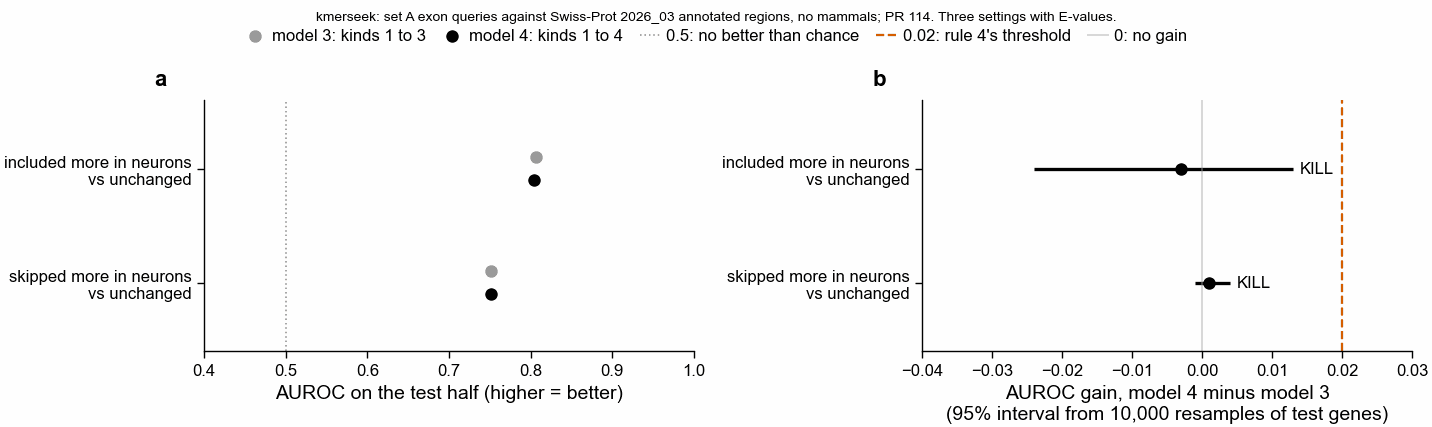

In [28]:
# AUROC of both models on the test half (a), and the gain with its 95% interval against rule 4's 0.02 (b).
fig, (ax_a, ax_b) = pf.figure(pf.TWO_COLUMN_MM, 55, ncols=2)
names = [r["comparison"].replace(" vs unchanged", "\nvs unchanged") for r in stop4]
y = np.arange(len(stop4))[::-1].astype(float)
for model, col, colour, dy in [
    ("model 3: kinds 1 to 3", "AUROC model 3", pf.GREY, 0.1),
    ("model 4: kinds 1 to 4", "AUROC model 4", "black", -0.1),
]:
    ax_a.scatter(stop4_table[col], y + dy, s=16, color=colour, label=model, zorder=3)
ax_a.axvline(0.5, color=pf.GREY, lw=0.6, ls=":", label="0.5: no better than chance")
ax_a.set_yticks(y, names)
ax_a.set_ylim(-0.6, len(stop4) - 0.4)
ax_a.set_xlim(0.4, 1.0)
ax_a.set_xlabel("AUROC on the test half (higher = better)")
pf.panel_label(ax_a, "a")
for yi, r in zip(y, stop4):
    ax_b.hlines(yi, r["gain 95% low"], r["gain 95% high"], color="black", lw=1.2)
    ax_b.scatter(r["gain"], yi, s=16, color="black", zorder=3)
    ax_b.text(
        r["gain 95% high"] + 0.001, yi, r["verdict"], va="center", ha="left", fontsize=6
    )
ax_b.axvline(
    MIN_GAIN,
    color=pf.OKABE_ITO["vermillion"],
    lw=0.8,
    ls="--",
    label="0.02: rule 4's threshold",
)
ax_b.axvline(0, color=pf.GREY, lw=0.6, ls="-", alpha=0.5, label="0: no gain")
ax_b.set_yticks(y, names)
ax_b.set_ylim(-0.6, len(stop4) - 0.4)
ax_b.set_xlim(min(-0.04, min(r["gain 95% low"] for r in stop4) - 0.005), 0.03)
ax_b.set_xlabel(
    "AUROC gain, model 4 minus model 3\n(95% interval from 10,000 resamples of test genes)"
)
pf.panel_label(ax_b, "b")
pf.shared_legend(fig, ncol=5, title=TOOL_LINE, title_fontsize=5)
save_figure(fig, FIGURES / "342_setA_stop4_auroc_gain_model4_vs_model3_test_half")
print(
    stop4_table.select(
        "comparison",
        "AUROC model 3",
        "AUROC model 4",
        "gain",
        "gain 95% low",
        "gain 95% high",
        "verdict",
    )
)

In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict

# Not rule 4, and no verdict comes from it. (a) Kind 4 alone, scored by 5-fold cross-validation on the
# tune half only (folds split by gene), to see whether it carries any signal on its own. (b) The test-half
# gain with C fixed at 1 for both models, to see whether the verdict depends on the strong penalty
# cross-validation picked (C = 0.0001 for "skipped more", the smallest value tried).
side = []
for changed in ["included more in neurons", "skipped more in neurons"]:
    sub = data.filter(pl.col("outcome").is_in([changed, "unchanged"]))
    tune = sub.filter(pl.col("half") == "tune")
    y_tune = (tune["outcome"] == changed).cast(pl.Int8).to_numpy()
    folds = list(
        GroupKFold(n_splits=N_FOLDS).split(
            tune, y_tune, groups=tune["gene_name"].to_numpy()
        )
    )
    cv_score = cross_val_predict(
        make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000)),
        design(tune, KIND4).to_numpy(),
        y_tune,
        cv=folds,
        method="predict_proba",
    )[:, 1]
    fixed = {}
    for name, cols in [("3", KIND123), ("4", KIND123 + KIND4)]:
        test = sub.filter(pl.col("half") == "test")
        X_tune = design(tune, cols)
        X_test = design(
            test, cols, {c[:-8] for c in X_tune.columns if c.endswith("_missing")}
        ).select(X_tune.columns)
        m = make_pipeline(
            StandardScaler(), LogisticRegression(C=1.0, max_iter=5000)
        ).fit(X_tune.to_numpy(), y_tune)
        y_test = (test["outcome"] == changed).cast(pl.Int8).to_numpy()
        fixed[name] = auroc(y_test, m.predict_proba(X_test.to_numpy())[:, 1])
    side.append(
        {
            "comparison": f"{changed} vs unchanged",
            "kind 4 alone, tune-half cross-validated AUROC": round(
                auroc(y_tune, cv_score), 3
            ),
            "test gain with C = 1": round(fixed["4"] - fixed["3"], 3),
            "AUROC model 3, C = 1": round(fixed["3"], 3),
            "AUROC model 4, C = 1": round(fixed["4"], 3),
        }
    )
with pl.Config(tbl_cols=-1, tbl_width_chars=250):
    print(pl.DataFrame(side))

shape: (2, 5)
┌─────────────────────────────────┬─────────────────────────────────┬──────────────────────┬──────────────────────┬──────────────────────┐
│ comparison                      ┆ kind 4 alone, tune-half cross-… ┆ test gain with C = 1 ┆ AUROC model 3, C = 1 ┆ AUROC model 4, C = 1 │
│ ---                             ┆ ---                             ┆ ---                  ┆ ---                  ┆ ---                  │
│ str                             ┆ f64                             ┆ f64                  ┆ f64                  ┆ f64                  │
╞═════════════════════════════════╪═════════════════════════════════╪══════════════════════╪══════════════════════╪══════════════════════╡
│ included more in neurons vs un… ┆ 0.531                           ┆ -0.012               ┆ 0.806                ┆ 0.794                │
│ skipped more in neurons vs unc… ┆ 0.448                           ┆ -0.009               ┆ 0.737                ┆ 0.728                │
└────────────

## Summary and conclusions

A transferred k-mer label does not add the required 0.02 AUROC to the baseline models for
set A neuronal splicing. Rule 4 gives KILL in both comparisons for the three settings tested.

* **Included more in neurons against unchanged** (92 and 1_572 test exons): AUROC 0.807 with kinds 1
  to 3 and 0.804 with kind 4 added. The gain is −0.003, 95% interval −0.024 to +0.013, entirely
  below 0.02.
* **Skipped more in neurons against unchanged** (48 and 1_572 test exons): AUROC 0.751 and 0.752,
  gain +0.001, interval −0.001 to +0.004. Cross-validation chose the strongest penalty tried
  (C = 0.0001) for both models, and the class is under the 100 exons rule 4 asks for. Two checks
  outside rule 4 point the same way. Kind 4 on its own predicts neither class on the tune half
  (cross-validated AUROC 0.531 and 0.448). With C fixed at 1, adding kind 4 lowers the test AUROC
  in both comparisons (by 0.012 and 0.009).
* **Predictions.** P1 holds (changed exons are more disordered, section 2). P2 fails: 36.8% of
  exons have a call at E < 1, against under 30% predicted. P3 does not hold: hit strength does not
  follow IUPred, AILMV share or SEG share (|ρ| at most 0.09). P4 holds: KILL in both comparisons.
* **What kmerseek found.** 1_063 of 4_513 exons (23.6%) have a hit at the decoy-matched cutoffs.
  The strongest hits are folded domains of related proteins at 76% to 91% identical residues.
* **Limits.** Kind 4 comes from three of the four settings Stop 0 named: protein20 k = 5 has no
  E-values with kmerseek tag `nb342-kmerseek-9ce5865` (closed-form match probability 0.000). The
  three settings' E-values are off by 7 to 113 times in different directions; the decoy-matched
  cutoffs correct for that in the hit calls, but −log10 E of the best hit mixes settings whose E
  means different things.
* **Decision.** As Stop 0 set out, exon function stays with kinds 1 to 3 plus Exon Ontology. The
  follow-up with TDP-43 loss in motor neurons and a PhaSePro/DisProt index is not started on this
  result.